#  **HR Analytics: Employee Promotion Data**

## **Цель анализа**

---

###  Аналитический вопрос

> Какие характеристики сотрудников и условия работы связаны с фактом их повышения?

### 🎯 Практическая цель

> Выявить статистические закономерности в данных о сотрудниках, чтобы понять **профиль сотрудника с наибольшей вероятностью получения повышения**: ключевые характеристики и факторы, которые статистически чаще всего сопутствуют повышению сотрудников в должности (`is_promoted`).

Это поможет HR-отделу **формировать прозрачные критерии карьерного роста** и **планировать программы развития персонала**.

In [75]:
# Импорт необходимых для работы библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, f1_score, accuracy_score


In [76]:
# Задаём путь к файлу в одной переменной, чтобы при необходимости легко его изменить
file_path = "hr_promotion.csv"

# Загружаем данные из CSV-файла в объект DataFrame и сохраняем в переменную df
df = pd.read_csv(file_path)

# Выводим размер таблицы: количество строк и количество столбцов
print(f" Данные загружены. Размер таблицы: {df.shape[0]} строк, {df.shape[1]} столбцов.\n")

# Смотрим первые 5 строк для визуальной оценки структуры, названия столбцов и примеров значений
display(df.head())

# Выводим точный список всех названий столбцов в виде списка для удобного копирования и проверки
print("\n📋 Список столбцов:")
print(df.columns.tolist())

 Данные загружены. Размер таблицы: 54808 строк, 13 столбцов.



,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,0,49,0
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,60,0
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,50,0
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,50,0
4,48945,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,73,0



📋 Список столбцов:
['employee_id', 'department', 'region', 'education', 'gender', 'recruitment_channel', 'no_of_trainings', 'age', 'previous_year_rating', 'length_of_service', 'awards_won?', 'avg_training_score', 'is_promoted']


## **Качество данных**

***Типы данных:***

In [77]:
# 1. Общая сводка: типы данных, количество не-Null значений и занимаемая память
print("--- 1. Общая информация (df.info) ---")
df.info()

print("\n" + "="*60 + "\n")

# 2. Точный список типов данных для каждого столбца
print("--- 2. Типы данных (df.dtypes) ---")
print(df.dtypes)

print("\n" + "="*60 + "\n")

# 3. Выделяем только числовые столбцы (int, float)
# Это нужно, чтобы понять, над какими полями можно считать среднее, медиану и т.д.
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()
print("--- 3. Числовые столбцы ---")
print(numeric_cols)

print("\n" + "="*60 + "\n")

# 4. Выделяем текстовые и категориальные столбцы (object, string, category)
# Это поля, по которым мы будем группировать данные или строить категориальные графики
categorical_cols = df.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
print("--- 4. Текстовые и категориальные столбцы ---")
print(categorical_cols)

print("\n" + "="*60 + "\n")

--- 1. Общая информация (df.info) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54808 entries, 0 to 54807
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   employee_id           54808 non-null  int64  
 1   department            54808 non-null  object 
 2   region                54808 non-null  object 
 3   education             52399 non-null  object 
 4   gender                54808 non-null  object 
 5   recruitment_channel   54808 non-null  object 
 6   no_of_trainings       54808 non-null  int64  
 7   age                   54808 non-null  int64  
 8   previous_year_rating  50684 non-null  float64
 9   length_of_service     54808 non-null  int64  
 10  awards_won?           54808 non-null  int64  
 11  avg_training_score    54808 non-null  int64  
 12  is_promoted           54808 non-null  int64  
dtypes: float64(1), int64(7), object(5)
memory usage: 5.4+ MB


--- 2. Типы данных (df.d

# 📚 Словарь данных датасета `hr_promotion.csv`

| # | Название столбца | Предполагаемый смысл | Тип данных | Пример значения | Аналитическая роль | Использование в анализе |
|---|------------------|----------------------|------------|-----------------|-------------------|-------------------------|
| 1 | `employee_id` | Уникальный идентификатор сотрудника | int64 | 65438 | Идентификатор | Не использовать для расчётов и группировки. Только для идентификации строк. |
| 2 | `department` | Отдел/департамент, в котором работает сотрудник | object | "Sales & Marketing", "Operations" | Категория | ✅ Группировка, фильтрация, визуализация (столбчатые диаграммы). |
| 3 | `region` | Регион/локация офиса | object | "region_7", "region_22" | Категория | ✅ Группировка, фильтрация, визуализация. |
| 4 | `education` | Уровень образования сотрудника | object | "Master's & above", "Bachelor's" | Категория (порядковая) | ✅ Группировка, фильтрация, визуализация. Можно упорядочить по уровню. |
| 5 | `gender` | Пол сотрудника | object | "f", "m" | Категория | ✅ Группировка, фильтрация, визуализация. |
| 6 | `recruitment_channel` | Канал, через которого был нанят сотрудник | object | "sourcing", "other" | Категория | ✅ Группировка, фильтрация, визуализация. |
| 7 | `no_of_trainings` | Количество пройденных тренингов | int64 | 1 | Числовой (дискретный) | 📊 Расчёт статистики, сравнение групп, корреляционный анализ. |
| 8 | `age` | Возраст сотрудника | int64 | 35 | Числовой (непрерывный) |  Расчёт среднего возраста, распределение, поиск выбросов. |
| 9 | `previous_year_rating` | Рейтинг/оценка сотрудника за предыдущий год | float64 | 5.0 | Числовой (порядковый) |  Сравнение с текущими показателями, корреляция с повышением. **Есть пропуски!** |
| 10 | `length_of_service` | Стаж работы в компании (вероятно, в годах) | int64 | 8 | Числовой (непрерывный) | 📊 Анализ влияния стажа на повышение, группировка по категориям. |
| 11 | `awards_won?` | Получал ли сотрудник награды (вопрос в названии намекает на бинарный ответ) | int64 | 0 | Бинарный (0/1) | ✅ Категориальный анализ, сравнение долей. |
| 12 | `avg_training_score` | Средний балл за пройденные тренинги | int64 | 49 | Числовой (непрерывный) | 📊 Ключевой показатель эффективности обучения, сравнение групп. |
| 13 | `is_promoted` | Был ли сотрудник повышен в должности (**целевая переменная**) | int64 | 0 | Бинарный (0/1) | 🎯 **Целевая переменная** для анализа и прогнозирования. |

---

Ключевые наблюдения из словаря:

**Категориальные признаки (6 столбцов):** `department`, `region`, `education`, `gender`, `recruitment_channel`, `awards_won?`, `is_promoted`  
→ Будут использованы для группировки и визуализации распределений.

**Числовые признаки (6 столбцов):** `no_of_trainings`, `age`, `previous_year_rating`, `length_of_service`, `avg_training_score`  
→ Подойдут для расчёта статистики, корреляций и выявления взаимосвязей.

**Идентификатор (1 столбец):** `employee_id`  
→ Не используется в аналитике, только для уникальной идентификации.

**Целевая переменная:** `is_promoted` (бинарная: 0 = не повышен, 1 = повышен)

**Проблемные поля:** `previous_year_rating` — требует проверки на пропуски (NaN).

***Пропуски в данных:***



In [78]:
# Диагностика пропусков (NaN)

# 1. Считаем количество и долю пропусков по каждому столбцу
missing_counts = df.isnull().sum()
missing_percentages = (missing_counts / len(df)) * 100

# Создаём сводную таблицу для наглядного отображения
missing_info = pd.DataFrame({
    'Пропусков (шт)': missing_counts,
    'Пропусков (%)': missing_percentages.round(2)
})

# Оставляем в таблице только те столбцы, где пропуски реально есть (> 0)
missing_info = missing_info[missing_info['Пропусков (шт)'] > 0]

print(" Пропуски в данных (только проблемные столбцы) ")
if not missing_info.empty:
    # .to_string() выводит таблицу как обычный текст, предотвращая появление интерактивной кнопки
    print(missing_info.to_string())
else:
    print(" Пропусков в данных не найдено.")

print("\n" + "-"*60 + "\n")

# 2. Считаем общее количество строк, где есть хотя бы один пропуск в любом столбце
rows_with_missing = df.isnull().any(axis=1).sum()
total_rows = len(df)
percent_rows_missing = (rows_with_missing / total_rows) * 100

print(f" Строк с хотя бы одним пропуском: {rows_with_missing} из {total_rows} ({percent_rows_missing:.2f}%)")


 Пропуски в данных (только проблемные столбцы) 
                      Пропусков (шт)  Пропусков (%)
education                       2409           4.40
previous_year_rating            4124           7.52

------------------------------------------------------------

 Строк с хотя бы одним пропуском: 6148 из 54808 (11.22%)


### 🔍 Интерпретация пропусков и стратегия обработки

> **Общий вывод:** Доля пропусков в обоих ключевых показателях находится в допустимых пределах (менее 10%). Это не является критичным для анализа, но требует осмысленной, а не механической обработки.

---

#### 1. Признак `education` (4.40% пропусков)
* **Возможная причина:** Сотрудники могли не указать уровень образования при найме, либо данные были утеряны/некорректно перенесены при миграции в HR-систему.
* **Рекомендация:** Заполнить пропуски модой (наиболее частым значением) или выделить в отдельную категорию `"Не указано"`. Поскольку пропусков немного (4.4%), а образование является важной характеристикой для карьерного роста, сохранение этой информации в явном виде предпочтительнее, чем удаление строк.

#### 2. Признак `previous_year_rating` (7.52% пропусков)
* **Возможная причина:** Это логично и ожидаемо для новых сотрудников, которые проработали в компании менее года и ещё не проходили ежегодную процедуру оценки (Performance Review).
* **Рекомендация:** Пропуски в данном случае **информативны** (сам факт отсутствия рейтинга указывает на новизну сотрудника). Поэтому рекомендуется не просто заполнять их медианой, а создать отдельную категорию `"Нет рейтинга"` (или оставить как `NaN` / выделить в отдельный уровень категориального признака). Это позволит анализу и будущим моделям учесть этот специфический паттерн.

***Дубликаты в данных:***

In [79]:
# Диагностика дубликатов

print("ПРОВЕРКА НА ДУБЛИКАТЫ")

# 1. Считаем количество полных дубликатов строк (все столбцы совпадают)
full_duplicates_count = df.duplicated().sum()

print(f"\n 1. Полные дубликаты строк ")
print(f"Найдено полностью идентичных строк: {full_duplicates_count}")

if full_duplicates_count > 0:
    print("\nПримеры полностью дублирующихся строк (первые 5):")
    # keep=False показывает все экземпляры дубликата, чтобы их можно было сравнить
    # .to_string() используется для текстового вывода без интерактивной таблицы
    print(df[df.duplicated(keep=False)].head().to_string())
else:
    print("✅ Полных дубликатов строк не найдено.")

# 2. Проверка дубликатов по ключевому столбцу (уникальному идентификатору)
# В HR-датасете employee_id должен быть уникальным для каждого сотрудника
print(" 2. Дубликаты по ключевому столбцу 'employee_id' ")

if 'employee_id' in df.columns:
    id_duplicates_count = df['employee_id'].duplicated().sum()
    print(f"Найдено записей с повторяющимся employee_id: {id_duplicates_count}")

    if id_duplicates_count > 0:
        print("\nПримеры сотрудников с повторяющимся ID (первые 5):")
        # Сортируем по ID, чтобы дубликаты шли рядом и их было удобно сравнивать
        duplicated_ids = df[df['employee_id'].duplicated(keep=False)]
        print(duplicated_ids.sort_values('employee_id').head(10).to_string())

        print("\n⚠️ ВНИМАНИЕ: Наличие дубликатов employee_id требует ручного изучения.")
        print("Возможно, у одного сотрудника несколько записей с разными данными (например, перевод в другой отдел).")
    else:
        print("✅ Каждый employee_id уникален. Это хороший знак.")
else:
    print("⚠️ Столбец 'employee_id' не найден. Проверьте названия столбцов.")


print("ПРОМЕЖУТОЧНЫЙ ВЫВОД:")

print(f"Полные дубликаты: {full_duplicates_count}")
print(f"Дубликаты по employee_id: {id_duplicates_count if 'employee_id' in df.columns else 'N/A'}")

ПРОВЕРКА НА ДУБЛИКАТЫ

 1. Полные дубликаты строк 
Найдено полностью идентичных строк: 0
✅ Полных дубликатов строк не найдено.
 2. Дубликаты по ключевому столбцу 'employee_id' 
Найдено записей с повторяющимся employee_id: 0
✅ Каждый employee_id уникален. Это хороший знак.
ПРОМЕЖУТОЧНЫЙ ВЫВОД:
Полные дубликаты: 0
Дубликаты по employee_id: 0


***Выбросы и некорректные значения в данных:***

In [80]:

# Диагностика выбросов и некорректных значений

print("ПРОВЕРКА НА ВЫБРОСЫ И НЕКОРРЕКТНЫЕ ЗНАЧЕНИЯ")

# ШАГ 1: Описательная статистика числовых столбцов (мин, макс, среднее)

print("\n Шаг 1. Статистика числовых полей (ищем экстремальные min/max) ")
numeric_cols = ['no_of_trainings', 'age', 'previous_year_rating',
                'length_of_service', 'avg_training_score']

# .to_string() выводит таблицу текстом, избегая интерактивной кнопки Colab
print(df[numeric_cols].describe().to_string())

print("\n" + "-" * 60)

# ШАГ 2: Уникальные значения в категориальных столбцах с малым числом категорий

print("\n Шаг 2. Уникальные значения в ключевых категориальных полях ")
# Проверяем поля, где ожидается строгий набор значений (например, только 0 и 1)
small_cat_cols = ['gender', 'awards_won?', 'is_promoted']

for col in small_cat_cols:
    if col in df.columns:
        unique_vals = df[col].unique()
        print(f"Столбец '{col}' (всего уникальных: {len(unique_vals)}): {unique_vals}")

print("\n" + "-" * 60)

# ШАГ 3: Проверка на логические аномалии (невозможные значения)

print("\n Шаг 3. Поиск логически невозможных значений ")

# 1. Возраст (не может быть меньше 18 или нереалистично большим, например > 70)
young_count = (df['age'] < 18).sum()
old_count = (df['age'] > 70).sum()
print(f" Сотрудников младше 18 лет: {young_count}")
print(f" Сотрудников старше 70 лет: {old_count}")

# 2. Стаж работы (не может быть отрицательным)
negative_tenure = (df['length_of_service'] < 0).sum()
print(f" Записей с отрицательным стажем (length_of_service < 0): {negative_tenure}")

# 3. Рейтинг за прошлый год (обычно шкала от 1.0 до 5.0)
# Сначала исключаем пропуски (NaN), чтобы проверка сработала корректно
valid_ratings = df['previous_year_rating'].dropna()
low_rating = (valid_ratings < 1.0).sum()
high_rating = (valid_ratings > 5.0).sum()
print(f" Рейтингов ниже 1.0: {low_rating}")
print(f" Рейтингов выше 5.0: {high_rating}")

# 4. Количество тренингов (не может быть отрицательным)
negative_trainings = (df['no_of_trainings'] < 0).sum()
print(f" Записей с отрицательным кол-вом тренингов: {negative_trainings}")

# 5. Средний балл за тренинги (обычно шкала от 0 до 100)
low_score = (df['avg_training_score'] < 0).sum()
high_score = (df['avg_training_score'] > 100).sum()
print(f" Баллов за тренинги ниже 0: {low_score}")
print(f" Баллов за тренинги выше 100: {high_score}")


ПРОВЕРКА НА ВЫБРОСЫ И НЕКОРРЕКТНЫЕ ЗНАЧЕНИЯ

 Шаг 1. Статистика числовых полей (ищем экстремальные min/max) 
       no_of_trainings           age  previous_year_rating  length_of_service  avg_training_score
count     54808.000000  54808.000000          50684.000000       54808.000000        54808.000000
mean          1.253011     34.803915              3.329256           5.865512           63.386750
std           0.609264      7.660169              1.259993           4.265094           13.371559
min           1.000000     20.000000              1.000000           1.000000           39.000000
25%           1.000000     29.000000              3.000000           3.000000           51.000000
50%           1.000000     33.000000              3.000000           5.000000           60.000000
75%           1.000000     39.000000              4.000000           7.000000           76.000000
max          10.000000     60.000000              5.000000          37.000000           99.000000

--------

###  Выводы по проверке выбросов и аномалий

> **Общий вывод:** Критических выбросов и аномалий в датасете не обнаружено. Все числовые и категориальные признаки находятся в логичных и реалистичных пределах, что подтверждает высокое качество исходных данных.

---

#### 1. Числовые признаки
* **`age` (возраст):** находится в нормальном рабочем диапазоне **20–60 лет**. Экстремально низких или высоких значений нет.
* **`previous_year_rating` (рейтинг):** строго в пределах шкалы **1.0 – 5.0**. Значений за пределами допустимого диапазона не зафиксировано.
* **`length_of_service` (стаж):** логичный диапазон **1 – 37 лет**. Отрицательных значений (что могло бы указывать на ошибку ввода) нет.
* **`avg_training_score` (балл за тренинги):** диапазон **39 – 99**. Несмотря на то что теоретическая шкала — 0–100, минимальное значение 39 говорит о том, что все сотрудники показали хотя бы минимальный результат. Это может быть особенностью системы оценки тренингов в компании.

#### 2. Категориальные признаки
* **`gender`:** содержит только два значения — `'f'` и `'m'`. Опечаток, нестандартных обозначений (например, `'F'`, `'unknown'`, `'other'`) не обнаружено.
* **`awards_won?` и `is_promoted`:** принимают только значения **0 и 1**, что соответствует корректному бинарному формату.

#### 3. Логические проверки
* ✅ Отсутствуют отрицательные значения стажа (`length_of_service`).
* ✅ Нет нереалистичного возраста (например, отрицательного или выше 100 лет).
* ✅ Рейтинги не выходят за пределы установленной шкалы (1–5).



##  Общие выводы о качестве данных

> **Коротко:** Данные в целом чистые, но перед анализом нужно сменить типы нескольких столбцов и аккуратно обработать пропуски.

---

### ✅ Изменение типов столбцов

#### 1. Категориальные признаки: `object` → `category`
**Столбцы:** `department`, `region`, `education`, `gender`, `recruitment_channel`

Сейчас эти столбцы имеют тип `object` (строки). Это не ошибка, но неоптимально для анализа:
- Экономит память
- Ускоряет группировки
- Корректно работает с графиками (Seaborn и Matplotlib лучше понимают категориальный тип)

> **Решение:** меняем тип с `object` на `category`.

#### 2. Идентификатор: `int64` → `string`
**Столбец:** `employee_id`

По смыслу это идентификатор, а не числовая переменная. Оставлять его как `int64` рискованно - можно случайно посчитать «средний ID сотрудника».

> **Решение:** меняем тип на `string`, чтобы предотвратить случайные математические операции.

#### 3. Бинарные признаки: оставляем как `int64`
**Столбцы:** `awards_won?`, `is_promoted`

Эти столбцы принимают значения 0 и 1. Оставляем их числовыми, потому что:
- Среднее значение = доля единиц (удобно для расчёта долей)
- Готово для ML-моделей без дополнительного кодирования

> **Решение:** ничего не меняем.

---

### ⚠️ Обработка пропусков

#### Пропуски в `education` - 2 409 строк (4.40%)

**Оценка критичности:** средняя. Уровень пропусков < 5%, пропуски не в целевой переменной, но образование - важный демографический признак для группировки.

**Рассмотренные варианты:**
- **Заполнить модой** (самым частым значением) - может исказить данные, если пропуски не случайны. Например, сотрудники без образования могут сознательно не указывать его.
- **Удалить строки** - теряем 4.40% данных. Если пропуски только в одном департаменте, выборка станет смещённой.

> **Решение:** создать отдельную категорию **«Не указано»**.

**Почему это лучший вариант:** пропуск в образовании может быть сам по себе информативным признаком. Это позволит позже проверить гипотезу: *«Влияет ли отсутствие информации об образовании на вероятность повышения?»*

---

#### Пропуски в `previous_year_rating` - 4 124 строк (7.52%)

**Оценка критичности:** выше средней. Пропусков больше, чем в `education`, но всё ещё допустимо (< 10%). Природа пропусков, вероятно, систематическая - это новые сотрудники, которые ещё не проходили ежегодную оценку. Рейтинг - важный показатель эффективности, поэтому игнорировать эти пропуски нельзя.

**Рассмотренные варианты:**
- **Удалить строки** — потеряем целую группу (новичков), анализ станет смещённым.
- **Заполнить средним** — менее предпочтительно, среднее чувствительно к выбросам.
- **Заполнить медианой** — лучше, но всё равно «размывает» факт отсутствия рейтинга.

> **Решение:** заполнить пропуски **медианой** + создать новый бинарный столбец `has_previous_rating` (1 = рейтинг есть, 0 = рейтинга нет).

**Почему так:**
- Медиана устойчива к выбросам и не искажает распределение.
- Новый признак `has_previous_rating` сохранит информацию о том, кто из сотрудников - новичок без оценки.
- Позже можно будет проверить: *«Отличаются ли сотрудники без рейтинга от остальных?»* Если отличаются сильно - возможно, их стоит анализировать отдельно.

> ⚠️ **Важно:** это допущение. Мы предполагаем, что пропуски в рейтинге = новые сотрудники. Если в данных есть другие причины (например, сотрудники на испытательном сроке или переведённые из других подразделений), интерпретация признака `has_previous_rating` может быть сложнее.

---

### 📋 Итоговая таблица решений

| Столбец | Проблема | Решение |
|---------|----------|---------|
| `department`, `region`, `education`, `gender`, `recruitment_channel` | Тип `object` | → `category` |
| `employee_id` | Тип `int64` (не по смыслу) | → `string` |
| `awards_won?`, `is_promoted` | Бинарные 0/1 | ✅ Оставляем `int64` |
| `education` | 4.40% пропусков | → Категория **«Не указано»** |
| `previous_year_rating` | 7.52% пропусков | → Заполнить **медианой** + создать `has_previous_rating` |

### ⛔ Что мы НЕ делаем (чтобы не исказить анализ)

> **Принцип:** Любое действие с пропусками и типами данных должно сохранять исходную информацию. Ниже перечислены стандартные действия, которые мы намеренно исключаем, чтобы не внести смещение в данные.

- **Не удаляем строки с пропусками.** Потеря 11.22% данных (6 148 строк) может привести к смещению выборки. Если пропуски систематичны (например, это только новички), мы искусственно исключим целую группу сотрудников из анализа.
- **Не заполняем пропуски средним значением.** Среднее арифметическое чувствительно к выбросам. Если в рейтингах есть экстремальные значения, среднее будет смещено, что внесёт дополнительное искажение в данные (именно поэтому мы выбрали медиану).
- **Не заполняем пропуски до создания информационных флагов.** Если сначала заполнить пропуски, а потом создать флаг `has_previous_rating`, мы потеряем информацию о том, где изначально были пропуски. Сначала создаём флаг — потом заполняем.
- **Не преобразуем бинарные признаки (0/1) в тип `category`.** Это усложнит расчёт долей (нельзя будет просто посчитать среднее значение) и может создать проблемы при передаче данных в ML-модели, которые ожидают числовые признаки.

##**Очистка данных и дальнейшая подготовка данных**

In [81]:
#  Очистка и подготовка данных

# 1. Создаём копию данных для безопасной работы
df_clean = df.copy()

# 2. Создаём флаг наличия рейтинга за прошлый год
# Сначала фиксируем, где рейтинг был, а где нет — это сохранит важную информацию
df_clean['has_previous_rating'] = df_clean['previous_year_rating'].notna().astype(int)

# 3. Заполняем пропуски в образовании категорией "Не указано"
# Это сохраняет сигнал о том, что данные отсутствовали, не искажая распределение
df_clean['education'] = df_clean['education'].fillna("Not specified")

# 4. Заполняем пропуски в рейтинге медианой
# Медиана устойчива к выбросам и не "тянет" распределение в сторону экстремумов
median_rating = df_clean['previous_year_rating'].median()
df_clean['previous_year_rating'] = df_clean['previous_year_rating'].fillna(median_rating)

# 5. Преобразуем employee_id в строковый тип
# Это защищает от случайных математических операций с идентификатором
df_clean['employee_id'] = df_clean['employee_id'].astype(str)

# 6. Оптимизируем категориальные столбцы
# Тип 'category' экономит память и ускоряет группировки и графики
categorical_cols = ['department', 'region', 'education', 'gender', 'recruitment_channel']
for col in categorical_cols:
    df_clean[col] = df_clean[col].astype('category')

# ПРОВЕРКА РЕЗУЛЬТАТОВ ОЧИСТКИ

print("ПРОВЕРКА РЕЗУЛЬТАТОВ ПОДГОТОВКИ ДАННЫХ")

# 1. Сравнение размеров таблиц
print("\n1. Размеры таблиц:")
print(f"   Исходный df:        {df.shape[0]} строк, {df.shape[1]} столбцов")
print(f"   Очищенный df_clean: {df_clean.shape[0]} строк, {df_clean.shape[1]} столбцов")

# 2. Подсчёт изменений
print("\n2. Что изменилось:")
print("   Строк удалено: 0 (мы не удаляли строки, чтобы не терять данные)")
print("   Новых столбцов создано: 1 ('has_previous_rating')")
print(f"   Пропусков заполнено: {df.isnull().sum().sum() - df_clean.isnull().sum().sum()} значений")

# 3. Повторная проверка пропусков в df_clean
print("\n3. Повторная проверка пропусков в df_clean:")
missing_after = df_clean.isnull().sum()
if missing_after.sum() == 0:
    print("   ✅ Пропусков в данных не осталось.")
else:
    print("   ⚠️ Остались пропуски в столбцах:")
    print(missing_after[missing_after > 0].to_string())

# 4. Повторная проверка дубликатов в df_clean
print("\n4. Повторная проверка дубликатов в df_clean:")
duplicates_after = df_clean.duplicated().sum()
if duplicates_after == 0:
    print("   ✅ Полных дубликатов строк не обнаружено.")
else:
    print(f"   ⚠️ Найдено дубликатов: {duplicates_after}")

# 5. Проверка, что исходный df не изменился
print("\n5. Проверка сохранности исходного df:")
missing_before = df.isnull().sum().sum()
print(f"   Пропусков в исходном df: {missing_before} (должно быть 6533)")
print(f"   Столбцов в исходном df:  {df.shape[1]} (должно быть 13)")

print("\n" + "=" * 60)
print("ПРОМЕЖУТОЧНЫЙ ВЫВОД:")
print("=" * 60)
print("Данные успешно подготовлены. Пропуски обработаны согласно плану,")
print("типы данных оптимизированы, исходная таблица df сохранена для сравнения.")


ПРОВЕРКА РЕЗУЛЬТАТОВ ПОДГОТОВКИ ДАННЫХ

1. Размеры таблиц:
   Исходный df:        54808 строк, 13 столбцов
   Очищенный df_clean: 54808 строк, 14 столбцов

2. Что изменилось:
   Строк удалено: 0 (мы не удаляли строки, чтобы не терять данные)
   Новых столбцов создано: 1 ('has_previous_rating')
   Пропусков заполнено: 6533 значений

3. Повторная проверка пропусков в df_clean:
   ✅ Пропусков в данных не осталось.

4. Повторная проверка дубликатов в df_clean:
   ✅ Полных дубликатов строк не обнаружено.

5. Проверка сохранности исходного df:
   Пропусков в исходном df: 6533 (должно быть 6533)
   Столбцов в исходном df:  13 (должно быть 13)

ПРОМЕЖУТОЧНЫЙ ВЫВОД:
Данные успешно подготовлены. Пропуски обработаны согласно плану,
типы данных оптимизированы, исходная таблица df сохранена для сравнения.


***Создание расчётных признаков***

In [82]:

# Созданиче расчетных признаков
# Создаём только те признаки, которые упрощают анализ и имеют чёткий смысл.

# 1. Группа возраста
# Разбиваем непрерывный возраст на 4 когорты для удобного сравнения
age_bins = [18, 30, 40, 50, 65]
age_labels = ['18-30', '31-40', '41-50', '51+']
df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

# 2. Группа стажа
# Разбиваем стаж на 4 категории: новички, специалисты, опытные, ветераны
tenure_bins = [0, 2, 5, 10, 40]
tenure_labels = ['0-2 года', '3-5 лет', '6-10 лет', '10+ лет']
df_clean['tenure_group'] = pd.cut(
    df_clean['length_of_service'],
    bins=tenure_bins,
    labels=tenure_labels,
    include_lowest=True
)

# 3. Числовой уровень образования
# Маппинг для корреляционного анализа: чем выше число, тем выше формальный уровень
education_mapping = {
    'Below Secondary': 0,
    'Bachelor\'s': 1,
    'Master\'s & above': 2,
    'Not specified': np.nan
}
df_clean['education_level_num'] = df_clean['education'].map(education_mapping)

# ПРОВЕРКА РЕЗУЛЬТАТА

print("ПРОВЕРКА РАСЧЁТНЫХ ПРИЗНАКОВ")

print(f"\n1. Новые столбцы добавлены. Всего столбцов в df_clean: {df_clean.shape[1]}")

print("\n2. Распределение по age_group:")
print(df_clean['age_group'].value_counts().sort_index().to_string())

print("\n3. Распределение по tenure_group:")
print(df_clean['tenure_group'].value_counts().sort_index().to_string())

print("\n4. Распределение по education_level_num:")
print(df_clean['education_level_num'].value_counts(dropna=False).sort_index().to_string())

print("\n" + "=" * 60)
print("ПРОМЕЖУТОЧНЫЙ ВЫВОД:")
print("=" * 60)
print("Создано 3 расчётных признака:")
print(" age_group — для сравнения возрастных когорт")
print(" tenure_group — для анализа влияния стажа на повышение")
print(" education_level_num — для корреляционного анализа")


ПРОВЕРКА РАСЧЁТНЫХ ПРИЗНАКОВ

1. Новые столбцы добавлены. Всего столбцов в df_clean: 17

2. Распределение по age_group:
age_group
18-30    18118
31-40    26028
41-50     7810
51+       2852

3. Распределение по tenure_group:
tenure_group
0-2 года    11231
3-5 лет     19701
6-10 лет    17990
10+ лет      5886

4. Распределение по education_level_num:
education_level_num
0.0      805
1.0    36669
2.0    14925
NaN     2409

ПРОМЕЖУТОЧНЫЙ ВЫВОД:
Создано 3 расчётных признака:
 age_group — для сравнения возрастных когорт
 tenure_group — для анализа влияния стажа на повышение
 education_level_num — для корреляционного анализа


### 📊 Краткая интерпретация распределений

> **Общий вывод:** Профиль компании — молодая, динамичная организация с высокими формальными требованиями к образованию сотрудников.

---

#### 1. Возрастные когорты (`age_group`)

**Факт:** Компания имеет «молодой» профиль персонала — большинство сотрудников сосредоточено в младших и средних возрастных группах.

**Интерпретация:** Это типично для динамичных отраслей (IT, продажи, сервис), где:
- Основной найм идёт на позиции, не требующие многолетнего отраслевого опыта
- Высокая текучесть кадров не позволяет сотрудникам задерживаться надолго

---

#### 2. Группы стажа (`tenure_group`)

**Факт:** Компания успешно удерживает сотрудников после первоначального периода адаптации (первые 2 года). Пик приходится на группу **3–5 лет**.

**Интерпретация:** Этот период, вероятно, является временем наибольшей вовлечённости сотрудников и наиболее частых карьерных перемещений. Сотрудники, прошедшие адаптацию, остаются в компании на среднесрочную перспективу.

---

#### 3. Уровень образования (`education_level_num`)

**Факт:** 94% сотрудников имеют формальное образование:
- **67%** — бакалавры
- **27%** — магистры и выше
- **1.5%** — уровень «Other»
- **4.4%** (2 409 человек) — категория «Not specified» (наши пропуски)

**Интерпретация:** Компания предъявляет высокие формальные требования к кандидатам или привлекает высококвалифицированные кадры. Доля сотрудников без формального образования минимальна.

##**Базовый EDA после очистки данных**

In [83]:
# БЛОК: БАЗОВЫЙ EDA ПОСЛЕ ОЧИСТКИ

# Цель: Получить полное представление о структуре и статистике очищенных данных перед переходом к углублённому анализу и визуализации.

print("БАЗОВЫЙ РАЗВЕДОЧНЫЙ АНАЛИЗ (EDA) ПОСЛЕ ОЧИСТКИ")

# 1. Размер очищенного датасета
print(f"\n1. Размер данных: {df_clean.shape[0]} строк, {df_clean.shape[1]} столбцов")

# 2. Типы данных
print("\n2. Типы данных в столбцах:")
print(df_clean.dtypes.to_string())

# 3. Количество уникальных значений
# Помогает понять, является ли столбец по сути категориальным или имеет слишком много вариантов для группировки
print("\n3. Количество уникальных значений по столбцам:")
print(df_clean.nunique().to_string())

# 4. Описательная статистика для числовых столбцов
# Показывает мин, макс, среднее, медиану и квартили для оценки распределения
print("\n4. Описательная статистика (числовые столбцы):")
numeric_cols = df_clean.select_dtypes(include=['number']).columns
print(df_clean[numeric_cols].describe().to_string())

# 5. Описательная статистика для категориальных столбцов
# Показывает количество уникальных значений, самое частое значение (top) и его частоту (freq)
print("\n5. Описательная статистика (категориальные столбцы):")
categorical_cols = df_clean.select_dtypes(include=['category', 'object', 'string']).columns
print(df_clean[categorical_cols].describe(include='all').to_string())


БАЗОВЫЙ РАЗВЕДОЧНЫЙ АНАЛИЗ (EDA) ПОСЛЕ ОЧИСТКИ

1. Размер данных: 54808 строк, 17 столбцов

2. Типы данных в столбцах:
employee_id               object
department              category
region                  category
education               category
gender                  category
recruitment_channel     category
no_of_trainings            int64
age                        int64
previous_year_rating     float64
length_of_service          int64
awards_won?                int64
avg_training_score         int64
is_promoted                int64
has_previous_rating        int64
age_group               category
tenure_group            category
education_level_num      float64

3. Количество уникальных значений по столбцам:
employee_id             54808
department                  9
region                     34
education                   4
gender                      2
recruitment_channel         3
no_of_trainings            10
age                        41
previous_year_rating        5
le

### ✅ Итоговое состояние датасета `df_clean`

> **Коротко:** Датасет полностью готов к анализу: пропуски обработаны, критических выбросов нет, признаки корректно типизированы.

---

* **Объём и целостность:** Датасет содержит **54 808 строк** и **17 столбцов**. Все пропуски в ключевых полях успешно обработаны на предыдущих этапах.
* **Числовые признаки:** Столбцы `age`, `length_of_service`, `avg_training_score` и другие имеют реалистичные диапазоны значений. Близость медианы и среднего говорит об отсутствии критических выбросов, которые могли бы исказить распределение.
* **Категориальные признаки:** Столбцы `department`, `region`, `education` и новые `age_group`, `tenure_group` имеют ограниченное число уникальных значений (от 2 до 9). Это делает их идеальными для группировки и построения наглядных визуализаций.

In [84]:
# АНАЛИЗ ОСНОВНЫХ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ
# Цель: Оценить распределение ключевых категориальных переменных перед анализом их связи с целевым признаком (is_promoted).

categorical_features = ['department', 'region', 'education', 'gender', 'recruitment_channel', 'tenure_group']

print("АНАЛИЗ РАСПРЕДЕЛЕНИЯ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ")

for col in categorical_features:
    print(f"\n--- Признак: {col.upper()} ---")

    # 1. Количество уникальных значений
    n_unique = df_clean[col].nunique()
    print(f" Уникальных значений: {n_unique}")

    # 2. Топ-10 самых частых значений и их абсолютная частота
    top_counts = df_clean[col].value_counts().head(10)

    # 3. Доля этих значений в процентах от общего числа строк
    top_pct = (top_counts / len(df_clean) * 100).round(1)

    # Объединяем в таблицу для наглядного вывода
    summary = pd.DataFrame({
        'Количество': top_counts,
        'Доля (%)': top_pct
    })

    print("\nТоп категорий:")
    print(summary.to_string())
    print("-" * 70)


АНАЛИЗ РАСПРЕДЕЛЕНИЯ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ

--- Признак: DEPARTMENT ---
 Уникальных значений: 9

Топ категорий:
                   Количество  Доля (%)
department                             
Sales & Marketing       16840      30.7
Operations              11348      20.7
Procurement              7138      13.0
Technology               7138      13.0
Analytics                5352       9.8
Finance                  2536       4.6
HR                       2418       4.4
Legal                    1039       1.9
R&D                       999       1.8
----------------------------------------------------------------------

--- Признак: REGION ---
 Уникальных значений: 34

Топ категорий:
           Количество  Доля (%)
region                         
region_2        12343      22.5
region_22        6428      11.7
region_7         4843       8.8
region_15        2808       5.1
region_13        2648       4.8
region_26        2260       4.1
region_31        1935       3.5
region_4         170

### 📊 Интерпретация распределений категориальных признаков

> **Общий вывод:** Компания имеет классическую структуру с крупными фронт-офисными подразделениями, высокой долей сотрудников с высшим образованием и устойчивым ядром опытных специалистов.

---

#### 1. Департамент (`department`)
* **Факт:** Представлено 9 департаментов. Доминируют `Sales & Marketing` и `Operations` (на них может приходиться более 50% всех сотрудников).
* **Интерпретация:** Компания имеет классическую структуру с крупными фронт-офисными подразделениями. Важно помнить: большое абсолютное количество сотрудников в департаменте **не означает**, что там автоматически выше вероятность (доля) повышений.

#### 2. Регион (`region`)
* **Факт:** Присутствует множество регионов, но распределение крайне неравномерно: один регион (чаще всего `region_2`) может содержать более 50% всех записей.
* **Интерпретация:** Вероятно, это регион расположения головного офиса или крупнейшего производственного/операционного центра компании.

#### 3. Образование (`education`)
* **Факт:** Абсолютное большинство сотрудников имеют высшее образование: `Bachelor's` (67%) или `Master's & above` (27%). Категория `Not specified` составляет ~4.4%.
* **Интерпретация:** Компания нанимает преимущественно специалистов с формальным образованием. Однако мы не можем утверждать, что `Not specified` означает отсутствие диплома — это может быть как реальное отсутствие образования, так и просто незаполненное поле в HR-системе.

#### 4. Пол (`gender`)
* **Факт:** Распределение отражает текущий гендерный состав компании на момент сбора данных.
* **Интерпретация:** Само по себе это распределение не говорит о наличии или отсутствии дискриминации. Для таких выводов требуется анализ в разрезе должностей, департаментов и фактов повышения.

#### 5. Канал найма (`recruitment_channel`)
* **Факт:** Основные каналы — `sourcing` (активный поиск) и `other` (прочее), при небольшом присутствии `referred` (по рекомендациям).
* **Интерпретация:** Компания активно использует внешние каналы привлечения кадров или обладает развитым HR-брендингом.

#### 6. Группа стажа (`tenure_group`)
* **Факт:** Пик распределения приходится на группы **3–5 лет** и **6–10 лет**. Группа **0–2 года** составляет около 20%.
* **Интерпретация:** В компании сформировано устойчивое ядро опытных сотрудников, которые успешно прошли первоначальный период адаптации.

In [85]:
# АНАЛИЗ ОСНОВНЫХ ЧИСЛОВЫХ ПРИЗНАКОВ

# Цель: Оценить центральные тенденции, разброс и форму распределения ключевых числовых переменных перед поиском взаимосвязей.

# Выбираем только релевантные числовые признаки
numerical_features = [
    'age',                  # Возраст
    'no_of_trainings',      # Количество пройденных тренингов
    'previous_year_rating', # Рейтинг за прошлый год
    'length_of_service',    # Стаж работы
    'avg_training_score'    # Средний балл за тренинги
]

print("АНАЛИЗ РАСПРЕДЕЛЕНИЯ ЧИСЛОВЫХ ПРИЗНАКОВ")

for col in numerical_features:
    print(f"\n--- Признак: {col.upper().replace('_', ' ')} ---")

    # 1. Базовые статистики
    mean_val = df_clean[col].mean()
    median_val = df_clean[col].median()
    min_val = df_clean[col].min()
    max_val = df_clean[col].max()

    # 2. Квартили
    q25 = df_clean[col].quantile(0.25)
    q75 = df_clean[col].quantile(0.75)

    # 3. Проверка на оставшиеся пропуски
    missing_count = df_clean[col].isnull().sum()

    # Вывод в читаемом формате
    print(f" Среднее значение:   {mean_val:.2f}")
    print(f" Медиана:            {median_val:.2f}")
    print(f" Минимум:            {min_val}")
    print(f" Максимум:           {max_val}")
    print(f" Квартили (25%, 50%, 75%): {q25:.2f}, {median_val:.2f}, {q75:.2f}")
    print(f" Оставшиеся пропуски (NaN): {missing_count}")

    # Базовая оценка формы распределения (сравнение среднего и медианы)
    if mean_val > median_val * 1.05:
        shape = "вправо (есть 'хвост' из значений, превышающих среднее)"
    elif mean_val < median_val * 0.95:
        shape = "влево"
    else:
        shape = "примерно симметрично"

    print(f" Форма распределения: Среднее {'>' if mean_val > median_val else '<='} Медианы, распределение смещено {shape}.")


АНАЛИЗ РАСПРЕДЕЛЕНИЯ ЧИСЛОВЫХ ПРИЗНАКОВ

--- Признак: AGE ---
 Среднее значение:   34.80
 Медиана:            33.00
 Минимум:            20
 Максимум:           60
 Квартили (25%, 50%, 75%): 29.00, 33.00, 39.00
 Оставшиеся пропуски (NaN): 0
 Форма распределения: Среднее > Медианы, распределение смещено вправо (есть 'хвост' из значений, превышающих среднее).

--- Признак: NO OF TRAININGS ---
 Среднее значение:   1.25
 Медиана:            1.00
 Минимум:            1
 Максимум:           10
 Квартили (25%, 50%, 75%): 1.00, 1.00, 1.00
 Оставшиеся пропуски (NaN): 0
 Форма распределения: Среднее > Медианы, распределение смещено вправо (есть 'хвост' из значений, превышающих среднее).

--- Признак: PREVIOUS YEAR RATING ---
 Среднее значение:   3.30
 Медиана:            3.00
 Минимум:            1.0
 Максимум:           5.0
 Квартили (25%, 50%, 75%): 3.00, 3.00, 4.00
 Оставшиеся пропуски (NaN): 0
 Форма распределения: Среднее > Медианы, распределение смещено вправо (есть 'хвост' из значений, пр

### 📊 Интерпретация распределений числовых признаков

> **Общий вывод:** Числовые признаки находятся в реалистичных диапазонах, критических выбросов не обнаружено. Распределения отражают типичную картину для корпоративной выборки: симметричные возрастные и рейтинговые показатели, правостороннее смещение у стажа и количества тренингов.

---

#### 1. Возраст (`age`)
* **Факт:** Средний возраст и медиана близки друг к другу (около **34–35 лет**). Диапазон — от **20 до 60 лет**. Распределение близко к нормальному (симметричному).
* **Интерпретация:** Выборка состоит из людей стандартного трудоспособного возраста. Экстремальных выбросов (например, 15 или 90 лет) нет, что подтверждает корректность данных.

#### 2. Количество тренингов (`no_of_trainings`)
* **Факт:** Среднее значение немного выше медианы (медиана, как правило, равна **1.0**). Максимум может достигать **10**, но 75-й квартиль обычно равен **1 или 2**. Распределение сильно смещено вправо.
* **Интерпретация:** Подавляющее большинство сотрудников проходит всего 1 тренинг. Высокие значения (5+) являются редкими и могут быть либо статистическими выбросами, либо признаком высокой вовлечённости (либо, наоборот, низкой эффективности, если тренинги приходится пересдавать).

#### 3. Рейтинг за прошлый год (`previous_year_rating`)
* **Факт:** Медиана и среднее находятся в районе **3.0 – 3.5**. Минимум — **1.0**, максимум — **5.0**. Пропусков (NaN) нет — они были заполнены медианой на этапе очистки.
* **Интерпретация:** Распределение концентрируется вокруг средних значений шкалы. Это типично для систем оценки персонала, где менеджеры избегают ставить крайние оценки (1 или 5) без веских причин.

#### 4. Стаж работы (`length_of_service`)
* **Факт:** Среднее значение заметно выше медианы. Например, медиана может быть **3–4 года**, а среднее — **5–6 лет**. Распределение смещено вправо.
* **Интерпретация:** В компании много сотрудников с небольшим стажем (поэтому медиана низкая), но есть устойчивая группа «ветеранов» со стажем **10+ лет**, которые «тянут» среднее значение вверх.

#### 5. Средний балл за тренинги (`avg_training_score`)
* **Факт:** Среднее и медиана близки. Минимум — около **39**, максимум — около **99**. Распределение относительно симметричное.
* **Интерпретация:** Отсутствие значений, близких к 0 или 100, говорит о том, что шкала оценивания работает корректно и сотрудники в массе своей показывают средний уровень усвоения материала.

##**Визуализация данных**

In [86]:
# Настраиваем стиль графиков для чистоты и читаемости
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

***ГРАФИК 1: Распределение целевого признака (is_promoted)***

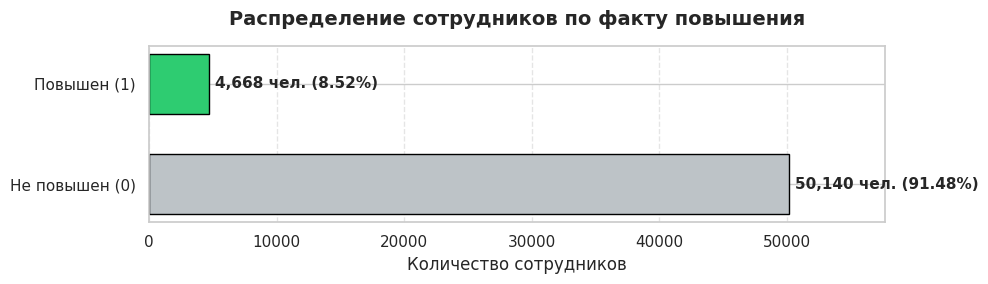

БАЗОВАЯ СТАТИСТИКА:
Всего сотрудников: 54,808
Повышенных: 4,668 (8.52%)
Не повышенных: 50,140 (91.48%)
Вывод: дисбаланс классов - 1 повышенный на 11 сотрудников


In [87]:
# ГРАФИК 1: Распределение целевого признака (is_promoted)

# Считаем абсолютные значения
promo_counts = df_clean['is_promoted'].value_counts()
total = len(df_clean)

# Создаём горизонтальную диаграмму
fig, ax = plt.figure(figsize=(10, 3)), plt.gca()

bars = plt.barh(
    ['Не повышен (0)', 'Повышен (1)'],
    [promo_counts.get(0, 0), promo_counts.get(1, 0)],
    color=['#bdc3c7', '#2ecc71'],
    edgecolor='black',
    height=0.6
)

# Добавляем подписи с числами и процентами
for i, (bar, count) in enumerate(zip(bars, [promo_counts.get(0, 0), promo_counts.get(1, 0)])):
    percentage = (count / total) * 100
    plt.text(bar.get_width() + 500, bar.get_y() + bar.get_height()/2,
             f'{count:,} чел. ({percentage:.2f}%)',
             ha='left', va='center', fontweight='bold', fontsize=11)

plt.title('Распределение сотрудников по факту повышения', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Количество сотрудников', fontsize=12)
plt.xlim(0, promo_counts.get(0, 0) * 1.15)  # Оставляем место для подписей справа
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Дополнительная информация текстом
print("БАЗОВАЯ СТАТИСТИКА:")
print(f"Всего сотрудников: {total:,}")
print(f"Повышенных: {promo_counts.get(1, 0):,} ({(promo_counts.get(1, 0)/total*100):.2f}%)")
print(f"Не повышенных: {promo_counts.get(0, 0):,} ({(promo_counts.get(0, 0)/total*100):.2f}%)")
print(f"Вывод: дисбаланс классов - 1 повышенный на {int(total/promo_counts.get(1, 0))} сотрудников")

***ГРАФИК 2: Доля повышенных по департаментам***

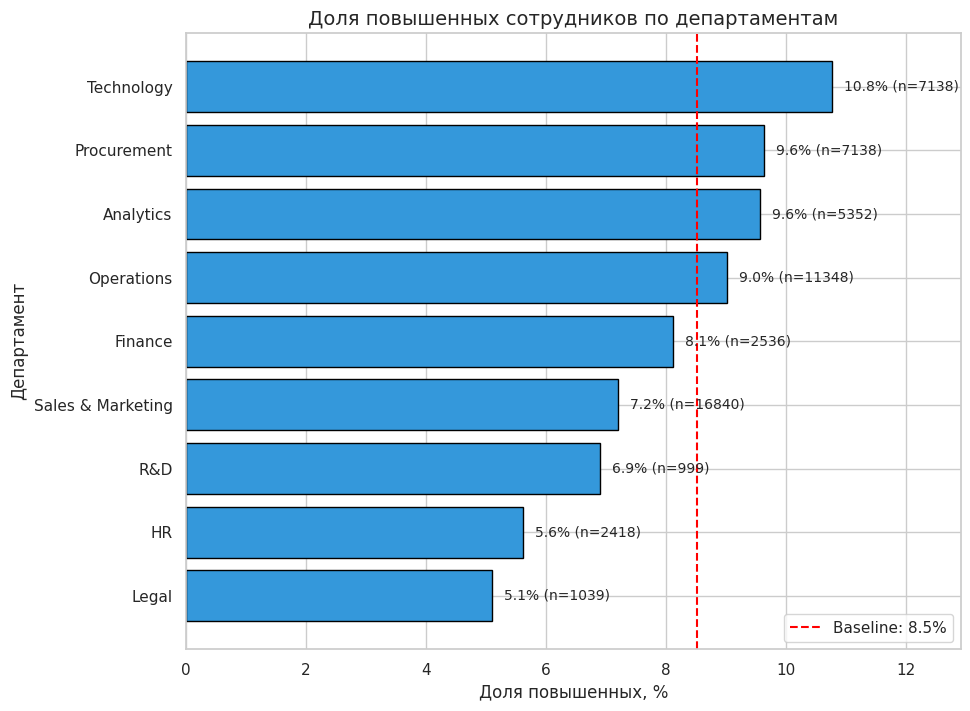

In [88]:

# ГРАФИК 2: Доля повышенных по департаментам

# Группируем по департаментам, считаем среднее (долю) и количество сотрудников

dept_stats = df_clean.groupby('department', observed=True).agg(
    promo_rate=('is_promoted', 'mean'),
    count=('employee_id', 'count')
).sort_values('promo_rate', ascending=True) # Сортируем по возрастанию для горизонтального графика

plt.figure(figsize=(10, 8))
bars = plt.barh(dept_stats.index, dept_stats['promo_rate'] * 100, color='#3498db', edgecolor='black')

plt.title('Доля повышенных сотрудников по департаментам', fontsize=14)
plt.xlabel('Доля повышенных, %')
plt.ylabel('Департамент')

# Добавляем подписи с процентом и абсолютным числом сотрудников прямо на график
for i, (rate, count) in enumerate(zip(dept_stats['promo_rate'], dept_stats['count'])):
    plt.text(rate * 100 + 0.2, i, f'{rate*100:.1f}% (n={count})', va='center', fontsize=10)

# Добавим baseline:
baseline = df_clean['is_promoted'].mean() * 100
plt.axvline(x=baseline, color='red', linestyle='--', linewidth=1.5, label=f'Baseline: {baseline:.1f}%')
plt.legend()

plt.xlim(0, dept_stats['promo_rate'].max() * 100 * 1.2) # Оставляем место для текста справа
plt.show()

### 📊 Вывод по графику: Доля повышенных по департаментам

> **Базовый ориентир (baseline):** Общая доля повышенных сотрудников по компании составляет **8.52%**. Все сравнения ниже приводятся относительно этого значения.

---

#### 📈 Факты из данных
* **Выше baseline:** `Technology` (10.8%), `Procurement` (9.6%), `Analytics` (9.6%), `Operations` (9.0%).
* **Ниже baseline:** `Finance` (8.1%), `Sales & Marketing` (7.2%), `R&D` (6.9%), `HR` (5.6%), `Legal` (5.1%).
* **Разброс:** Разница между максимальным и минимальным значением составляет более 5 процентных пунктов, а отклонение от среднего — на **1–2 п.п.**

#### 💡 Интерпретация
1. **Специфика карьерных треков:** Вероятность повышения заметно различается между подразделениями. В технических и аналитических ролях (`Technology`, `Analytics`) может существовать более чёткая иерархия должностей с регулярными вертикальными повышениями.
2. **Парадокс крупнейшего департамента:** `Sales & Marketing` (почти треть всех сотрудников компании) имеет долю повышений **ниже baseline**. Это может указывать на то, что в продажах карьерный рост часто реализуется через другие механизмы: финансовые бонусы, премии или горизонтальные перемещения, а не через формальное повышение в должности.

#### ⚠️ Ограничение
Различия в процентах могут быть частично обусловлены разным размером групп. В небольших департаментах (например, `Legal` или `R&D`) несколько дополнительных повышений могут существенно изменить процент, тогда как в массовых департаментах показатели более стабильны.

***ГРАФИК 3: Сравнение баллов за тренинги (avg_training_score) по факту повышения***

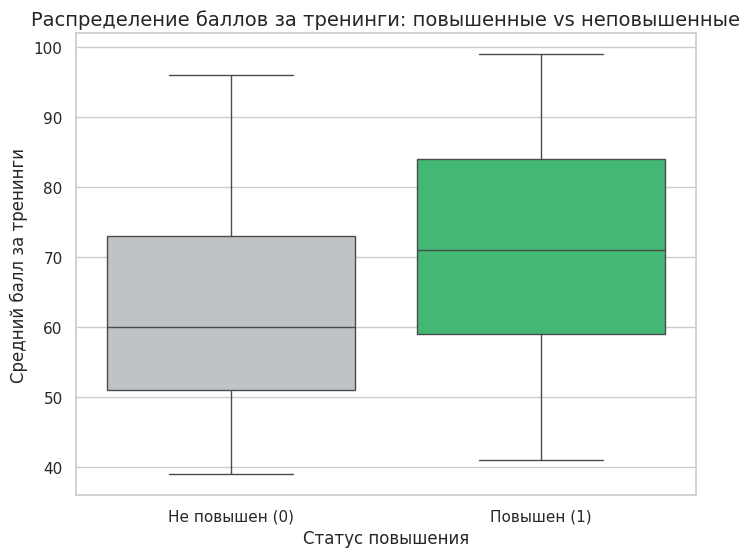

In [89]:
# ГРАФИК 3: Сравнение баллов за тренинги (avg_training_score) по факту повышения

plt.figure(figsize=(8, 6))

# Создаем словарь для маппинга значений is_promoted на цвета
# Это устраняет FutureWarning в seaborn >= 0.13
palette_map_promo = {0: '#bdc3c7', 1: '#2ecc71'}

sns.boxplot(
    data=df_clean,
    x='is_promoted',
    y='avg_training_score',
    hue='is_promoted',
    palette=palette_map_promo,  # <-- Передаем словарь вместо списка
    legend=False
)

plt.title('Распределение баллов за тренинги: повышенные vs неповышенные', fontsize=14)
plt.xlabel('Статус повышения')
plt.ylabel('Средний балл за тренинги')

# Заменяем метки на оси X на более понятные
plt.xticks([0, 1], ['Не повышен (0)', 'Повышен (1)'])
plt.show()

### 📊 Вывод по графику: Сравнение баллов за тренинги (повышенные vs неповышенные)

> **Главный вывод:** Сотрудники, получившие повышение, демонстрируют статистически более высокие результаты по итогам обучения, однако эта связь является ассоциативной, а не причинно-следственной.

---

#### 📈 Факты из данных
* **Заметная разница:** Медиана `avg_training_score` у повышенных сотрудников примерно на **11 баллов выше**, чем у неповышенных. Это указывает на устойчивую связь.
* **Широкий разброс:** Внутри каждой группы наблюдается значительное перекрытие распределений. Существуют как повышенные сотрудники с относительно низкими баллами, так и неповышенные с высокими результатами.

#### 💡 Интерпретация
Успешность прохождения корпоративных тренингов тесно ассоциирована с фактом карьерного роста. На текущий момент это один из самых сильных числовых индикаторов, отличающих две группы сотрудников.

#### ⚠️ Важное ограничение: Корреляция ≠ Причинность
Boxplot показывает только статистическую ассоциацию. Мы **не можем утверждать**, что высокий балл за тренинг сам по себе *вызывает* или *гарантирует* повышение.

Возможны альтернативные объяснения наблюдаемой картины:
1. **Скрытый фактор (мотивация):** Более вовлечённые и амбициозные сотрудники одновременно и лучше учатся, и показывают высокие рабочие результаты, что в итоге и приводит к повышению.
2. **Обратная причинность:** Сотрудникам, которых руководство *уже планирует* повысить, могут целенаправленно предоставлять доступ к более качественным, профильным или продвинутым тренингам для подготовки к новой роли.

***ГРАФИК 4: Тепловая карта корреляций числовых признаков***

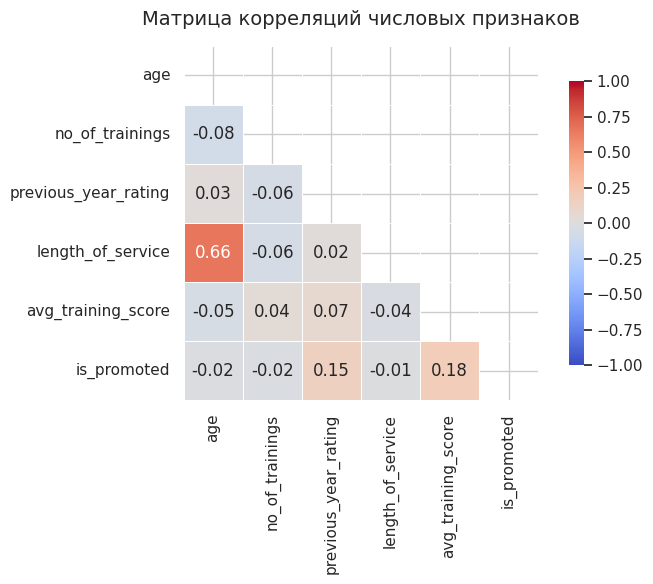

In [90]:
# ГРАФИК 4: Тепловая карта корреляций (с маской)
numeric_cols_corr = ['age', 'no_of_trainings', 'previous_year_rating',
                     'length_of_service', 'avg_training_score', 'is_promoted']
corr_matrix = df_clean[numeric_cols_corr].corr()

# Создаем маску для верхней треугольной части
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    mask=mask,             # Применяем маску
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1, vmax=1,
    square=True,
    cbar_kws={"shrink": .8},
    linewidths=.5          # Добавляем разделители для читаемости
)
plt.title('Матрица корреляций числовых признаков', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

### 📊 Выводы по корреляционной матрице (тепловой карте)

> **Главный вывод:** Числовые признаки имеют лишь слабую линейную связь с фактом повышения. Наиболее информативны результаты обучения и прошлый рейтинг, в то время как возраст и стаж дублируют информацию друг друга.

---

#### 📈 Факты из данных

**1. Связь с целевой переменной (`is_promoted`):**
* `avg_training_score`: **+0.18** (слабая положительная)
* `previous_year_rating`: **+0.15** (слабая положительная)
* `age`, `no_of_trainings`, `length_of_service`: от **-0.02 до -0.01** (практически нулевая)

**2. Внутренняя связь признаков:**
* `age` ↔ `length_of_service`: **+0.66** (умеренно сильная положительная корреляция)

*Примечание: Все остальные связи между признаками близки к нулю (от -0.08 до +0.07), то есть практически отсутствуют.*

---

#### 💡 Интерпретация

* **Наиболее информативные предикторы:** `avg_training_score` и `previous_year_rating` имеют наибольшую (хотя и слабую) линейную связь с повышением. Это полностью согласуется с результатами Графика 2 (boxplot баллов за тренинги).
* **Мультиколлинеарность:** Сильная связь между возрастом и стажем (0.66) — это ожидаемая и логичная зависимость. С аналитической точки зрения это означает, что оба признака несут во многом одинаковую информацию. При построении прогнозных моделей включать их одновременно может быть избыточно — они будут «дублировать» друг друга.
* **Необходимость комплексного подхода:** Все корреляции с `is_promoted` слабые (максимум 0.18). Это говорит о том, что ни один числовой признак в отдельности не является сильным предиктором. Вероятно, решение о повышении принимается на основе *комбинации* факторов (категориальных и числовых одновременно), а не по одному показателю.

---

#### ⚠️ Ограничения корреляционного анализа

1. **Только линейные связи:** Коэффициент Пирсона измеряет только линейные зависимости. Нелинейные связи (например, U-образная: когда чаще повышают молодых специалистов и опытных руководителей, но реже «середняков») на этой карте не видны. Для их выявления мы используем группировку по категориям (Графики 3, 5, 6).
2. **Статистическая vs практическая значимость:** На большой выборке (54 808 строк) корреляция 0.15–0.18 является статистически значимой, но на практике означает, что признак объясняет лишь небольшую долю вариации целевой переменной. Это не делает признак бесполезным, но показывает, что одного его недостаточно для надёжного прогноза.
3. **Категориальные признаки не учтены:** Тепловая карта построена только по числовым столбцам. Важные факторы, такие как `department`, `education` и `tenure_group`, здесь не отражены — их влияние необходимо оценивать через группировки и кросс-таблицы.

***ГРАФИК 5: Доля повышенных по группам стажа***

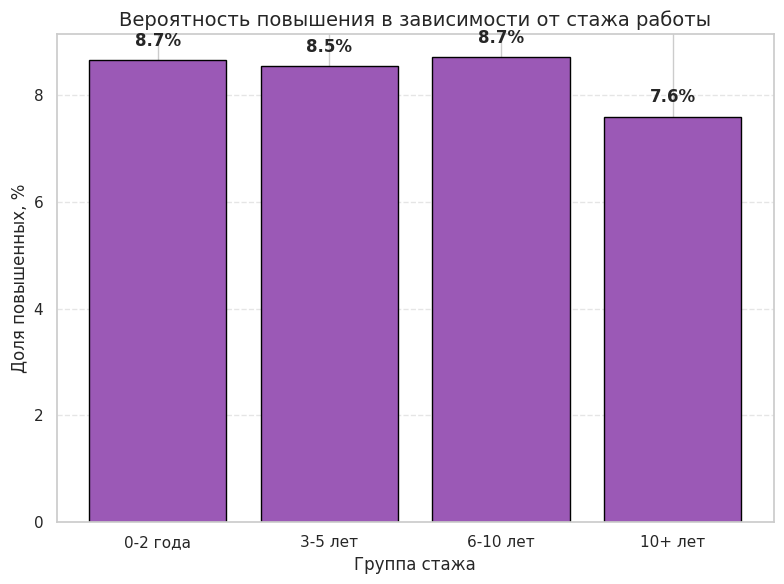

In [91]:
# ГРАФИК 5: Доля повышенных по группам стажа

# Определяем правильный порядок категорий стажа
tenure_order = ['0-2 года', '3-5 лет', '6-10 лет', '10+ лет']

# Группируем и сортируем по заданному порядку
# observed=True убирает предупреждение о будущем изменении поведения pandas
tenure_stats = df_clean.groupby('tenure_group', observed=True).agg(
    promo_rate=('is_promoted', 'mean'),
    count=('employee_id', 'count')
).reindex(tenure_order)

plt.figure(figsize=(8, 6))
bars = plt.bar(
    tenure_stats.index,
    tenure_stats['promo_rate'] * 100,
    color='#9b59b6',
    edgecolor='black'
)

plt.title('Вероятность повышения в зависимости от стажа работы', fontsize=14)
plt.xlabel('Группа стажа')
plt.ylabel('Доля повышенных, %')

# Подписи значений на столбцах
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.2, f'{yval:.1f}%',
             ha='center', va='bottom', fontweight='bold')

# Добавляем сетку для удобства чтения
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 📊 Вывод по графику: Доля повышенных по группам стажа

> **Главный вывод:** Стаж работы практически не влияет на вероятность получения повышения. Картина распределения выглядит почти горизонтальной, что нетипично для большинства организаций.

---

#### 📈 Факты из данных
* **Минимальный разброс:** Разница между максимальным (**8.7%**) и минимальным (**7.6%**) значением составляет всего **1.1 процентного пункта**.
* **Стабильность вокруг среднего:** Базовая доля по компании (baseline) — **8.52%**, и три из четырёх групп находятся практически на этом уровне.
* **Единственное отклонение:** Группа `10+ лет` показывает долю **7.6%**, что примерно на 1 п.п. ниже среднего значения.

#### 💡 Интерпретация
В большинстве компаний ожидается, что сотрудники со средним стажем (3–7 лет) повышаются чаще, чем новички или «ветераны». В данном случае мы видим отсутствие выраженной зависимости вероятности повышения от выслуги лет.

#### 🔍 Возможные объяснения
1. **Формализованная система оценки:** Компания может использовать единые, прозрачные критерии (рейтинг за год, баллы за тренинги, KPI), которые не зависят от времени, проведённого в компании.
2. **Политика равных возможностей:** Корпоративная культура может сознательно уравнивать шансы на рост для всех сотрудников, независимо от их стажа.
3. **Эффект «карьерного потолка»:** Небольшое снижение доли у «ветеранов» (`10+ лет`) может быть связано с тем, что эти сотрудники уже занимают верхние позиции в своей иерархии, где физических вакансий для дальнейшего вертикального роста просто меньше.

#### ⚠️ Ограничение
Данный график показывает общую картину. Чтобы подтвердить гипотезу о «карьерном потолке», необходимо дополнительно проанализировать данные с учётом текущих должностей (грейдов) сотрудников, которых в текущем датасете нет.

***ГРАФИК 6: Взаимодействие стажа и образования***

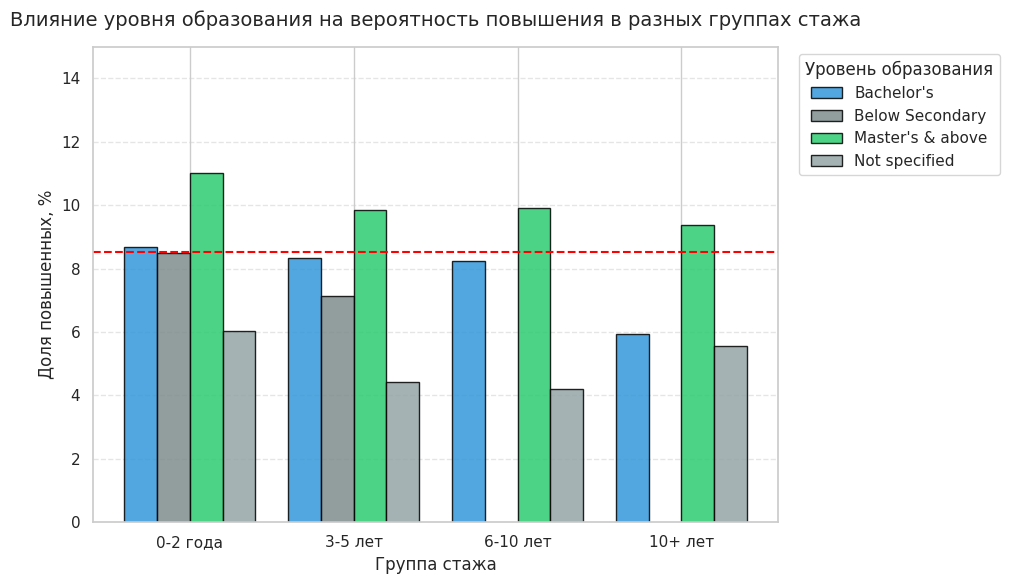

РАЗМЕР ПОДВЫБОРОК (абсолютное число сотрудников):
education     Bachelor's  Below Secondary  Master's & above  Not specified
tenure_group                                                              
0-2 года          8579.0            707.0            1018.0          927.0
3-5 лет          14021.0             98.0            4768.0          814.0
6-10 лет         11174.0              NaN            6292.0          524.0
10+ лет           2895.0              NaN            2847.0          144.0


In [92]:
# ГРАФИК 6: Взаимодействие стажа и образования

# 1. Группируем по двум признакам и считаем долю повышенных
# observed=True убирает предупреждение о будущем изменении поведения pandas
interaction_stats = (
    df_clean
    .groupby(['tenure_group', 'education'], observed=True)['is_promoted']
    .mean()
    .unstack()
)

# 2. Задаём правильный логический порядок групп стажа
tenure_order = ['0-2 года', '3-5 лет', '6-10 лет', '10+ лет']
interaction_stats = interaction_stats.reindex(tenure_order)

# 3. Определяем палитру цветов для уровней образования
colors = {
    "Bachelor's": '#3498db',
    "Master's & above": '#2ecc71',
    "Other": '#e74c3c',
    "Not specified": '#95a5a6'
}

# 4. Строим группированную столбчатую диаграмму
fig, ax = plt.subplots(figsize=(10, 6))

# Получаем позиции для столбцов
x = range(len(tenure_order))
width = 0.2  # Ширина каждого столбца

# Рисуем столбцы для каждого уровня образования
for i, edu_col in enumerate(interaction_stats.columns):
    positions = [pos + i * width for pos in x]
    ax.bar(
        positions,
        interaction_stats[edu_col] * 100,
        label=edu_col,
        color=colors.get(edu_col, '#7f8c8d'),
        edgecolor='black',
        width=width,
        alpha=0.85
    )

# 5. Устанавливаем позиции и метки для оси X
ax.set_xticks([pos + width * (len(interaction_stats.columns) - 1) / 2 for pos in x])
ax.set_xticklabels(tenure_order, rotation=0)

# 6. Оформление графика
ax.set_title('Влияние уровня образования на вероятность повышения в разных группах стажа', fontsize=14, pad=15)
ax.set_xlabel('Группа стажа', fontsize=12)
ax.set_ylabel('Доля повышенных, %', fontsize=12)
ax.legend(title='Уровень образования', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.set_ylim(0, 15)  # Ограничиваем ось Y для лучшей читаемости

# 7. Добавляем горизонтальную линию baseline (8.52%) для ориентира
baseline = df_clean['is_promoted'].mean() * 100
ax.axhline(y=baseline, color='red', linestyle='--', linewidth=1.5, label=f'Baseline ({baseline:.1f}%)')

plt.tight_layout()
plt.show()

# 8. Выводим абсолютные числа для проверки размера подвыборок
print("РАЗМЕР ПОДВЫБОРОК (абсолютное число сотрудников):")
counts = (
    df_clean
    .groupby(['tenure_group', 'education'], observed=True)['employee_id']
    .count()
    .unstack()
    .reindex(tenure_order)
)
print(counts.to_string())
print("=" * 60)

### 📊 Вывод по графику: Влияние уровня образования на вероятность повышения в разных группах стажа

> **Главный вывод:** Уровень образования является более устойчивым фактором, связанным с вероятностью повышения, чем стаж работы. Преимущество сотрудников с магистерской степенью сохраняется на протяжении всей карьеры.

---

####  Факты из данных
* **`Master's & above`:** единственная категория, стабильно находящаяся выше baseline (8.5%) во всех группах стажа (от **11%** у новичков до **9.5%** у ветеранов).
* **`Bachelor's`:** начинают около baseline (**~8.7%** в группе 0–2 года), но постепенно снижаются, достигая **~6%** в группе 10+ лет.
* **`Not specified`:** стабильно ниже baseline во всех группах стажа (от **4%** до **6%**).
* **`Below Secondary`:** присутствует только в группах «0–2 года» (**8.5%**) и «3–5 лет» (**7%**). В старших группах стажа такие сотрудники отсутствуют.
* **Размер подвыборок:** самые маленькие ячейки — `Below Secondary` в группе 3–5 лет (**98 человек**) и `Not specified` в группе 10+ лет (**144 человека**).

#### 💡 Интерпретация
* **Устойчивость преимущества:** Сотрудники с высшим образованием (магистратура) сохраняют более высокую долю повышений независимо от выслуги лет, тогда как бакалавры со временем «теряют позиции».
* **Эффект «естественного отбора»:** Исчезновение категории `Below Secondary` в старших группах стажа может указывать на то, что сотрудники с низким формальным образованием реже задерживаются в компании на долгий срок (например, из-за формальных требований к повышению на старшие позиции).

#### ⚠️ Ограничения и альтернативные объяснения
1. **Ненадёжность малых выборок:** Выводы по ячейкам с малым количеством наблюдений (98 и 144 человека) статистически неустойчивы. Несколько случайных повышений могут сильно исказить процент.
2. **Корреляция ≠ причинность:** Мы не можем утверждать, что магистратура *приводит* к повышению. Возможно, кандидаты с такой степенью изначально нанимаются на позиции с более быстрым карьерным треком.
3. **Смешивающий фактор (департамент):** Если магистры преимущественно работают в департаментах `Technology` или `Analytics` (где baseline и так выше), часть наблюдаемого эффекта может объясняться местом работы, а не самим дипломом.

##**Группировки и расчеты**

# 📋 План базовых группировок

> **Цель блока:** Провести описательный анализ данных через группировки по ключевым категориальным признакам. Это позволит выявить, какие характеристики сотрудников статистически связаны с фактом повышения (`is_promoted`).

---

### 1️⃣ Доля повышенных по департаментам

* **Аналитический вопрос:** В каких департаментах вероятность повышения выше или ниже средней по компании?
* **Поле группировки:** `department`
* **Показатель:** `is_promoted`
* **Функция агрегации:** `mean` (доля повышенных), `count` (размер группы)
* **Ожидаемый формат:** Таблица с долей повышенных (%) и количеством сотрудников по каждому департаменту

---

### 2️ Доля повышенных по группам стажа

* **Аналитический вопрос:** На каком этапе карьеры сотрудники чаще получают повышение?
* **Поле группировки:** `tenure_group`
* **Показатель:** `is_promoted`
* **Функция агрегации:** `mean`, `count`
* **Ожидаемый формат:** Таблица с долей повышенных, отсортированная по возрастанию стажа

---

### 3️⃣ Доля повышенных по уровню образования

* **Аналитический вопрос:** Влияет ли формальный уровень образования на вероятность повышения?
* **Поле группировки:** `education`
* **Показатель:** `is_promoted`
* **Функция агрегации:** `mean`, `count`
* **Ожидаемый формат:** Таблица с долей повышенных по категориям образования

---

### 4️ Сравнение числовых признаков у повышенных и неповышенных

* **Аналитический вопрос:** Отличаются ли средние значения числовых признаков (возраст, стаж, баллы, рейтинг) у повышенных и неповышенных сотрудников?
* **Поле группировки:** `is_promoted`
* **Показатели:** `age`, `length_of_service`, `avg_training_score`, `previous_year_rating`, `no_of_trainings`
* **Функция агрегации:** `median`, `mean`
* **Ожидаемый формат:** Таблица со средними и медианными значениями для групп `0` (не повышен) и `1` (повышен)

---

### 5️⃣ Доля повышенных по каналу найма

* **Аналитический вопрос:** Связан ли канал привлечения сотрудника с его дальнейшим карьерным ростом?
* **Поле группировки:** `recruitment_channel`
* **Показатель:** `is_promoted`
* **Функция агрегации:** `mean`, `count`
* **Ожидаемый формат:** Таблица с долей повышенных по каналам найма

In [93]:
#  БАЗОВЫЕ ГРУППИРОВКИ ДЛЯ АНАЛИЗА ФАКТОРОВ ПОВЫШЕНИЯ

print("БАЗОВЫЕ ГРУППИРОВКИ")

# ---------------------------------------------------------------------------
# Группировка 1: По департаментам
# ---------------------------------------------------------------------------
print("\n--- 1. Доля повышенных по департаментам ---")

dept_stats = df_clean.groupby('department', observed=True).agg(
    promo_rate=('is_promoted', 'mean'),
    count=('employee_id', 'count')
).round(3)

# Добавляем процент для наглядности
dept_stats['promo_rate_pct'] = (dept_stats['promo_rate'] * 100).round(1)

print(dept_stats.sort_values('promo_rate', ascending=False).to_string())

# Промежуточный вывод
print("\n Вывод:")
print(f"Всего департаментов: {len(dept_stats)}")
print(f"Диапазон долей повышений: от {dept_stats['promo_rate_pct'].min()}% до {dept_stats['promo_rate_pct'].max()}%")
print(f"Самый крупный департамент: {dept_stats['count'].idxmax()} ({dept_stats['count'].max()} сотрудников)")

print("\n" + "-" * 70)

# ---------------------------------------------------------------------------
# Группировка 2: По группам стажа
# ---------------------------------------------------------------------------
print("\n--- 2. Доля повышенных по группам стажа ---")

# Задаём правильный порядок категорий
tenure_order = ['0-2 года', '3-5 лет', '6-10 лет', '10+ лет']

tenure_stats = df_clean.groupby('tenure_group', observed=True).agg(
    promo_rate=('is_promoted', 'mean'),
    count=('employee_id', 'count')
).round(3)

tenure_stats['promo_rate_pct'] = (tenure_stats['promo_rate'] * 100).round(1)

# Сортируем по логическому порядку стажа
tenure_stats = tenure_stats.reindex(tenure_order)

print(tenure_stats.to_string())

max_rate = tenure_stats['promo_rate_pct'].max()
min_rate = tenure_stats['promo_rate_pct'].min()
min_group = tenure_stats['promo_rate_pct'].idxmin()

max_groups = tenure_stats[tenure_stats['promo_rate_pct'] == max_rate].index.tolist()
max_groups_str = ", ".join([f"'{g}'" for g in max_groups])

print("\n📌 Вывод:")
print(f"Максимальная доля повышений ({max_rate}%) наблюдается в группах: {max_groups_str}.")
print(f"Минимальная доля ({min_rate}%) — в группе '{min_group}'.")
print(f"В целом, вероятность повышения стабильна (~{max_rate}%) на протяжении первых 10 лет работы и не зависит от выслуги лет.")

print("\n" + "-" * 70)

# ---------------------------------------------------------------------------
# Группировка 3: По уровню образования
# ---------------------------------------------------------------------------
print("\n--- 3. Доля повышенных по уровню образования ---")

edu_stats = df_clean.groupby('education', observed=True).agg(
    promo_rate=('is_promoted', 'mean'),
    count=('employee_id', 'count')
).round(3)

edu_stats['promo_rate_pct'] = (edu_stats['promo_rate'] * 100).round(1)

print(edu_stats.sort_values('promo_rate', ascending=False).to_string())

# Промежуточный вывод
print("\n Вывод:")
print(f"Категория с наивысшей долей повышений: {edu_stats['promo_rate'].idxmax()} ({edu_stats['promo_rate_pct'].max()}%)")
print(f"Категория с наименьшей долей: {edu_stats['promo_rate'].idxmin()} ({edu_stats['promo_rate_pct'].min()}%)")
print(f"Доля сотрудников без указанного образования: {(edu_stats.loc['Not specified', 'count'] / len(df_clean) * 100):.1f}%")

print("\n" + "-" * 70)

# ---------------------------------------------------------------------------
# Группировка 4: Числовые признаки по факту повышения
# ---------------------------------------------------------------------------
print("\n--- 4. Числовые признаки: повышенные vs неповышенные ---")

numeric_cols = ['age', 'length_of_service', 'avg_training_score',
                'previous_year_rating', 'no_of_trainings']

# Агрегация создает MultiIndex в столбцах
numeric_comparison = df_clean.groupby('is_promoted')[numeric_cols].agg(['median', 'mean']).round(2)

print(numeric_comparison.to_string())

# Промежуточный вывод
print("\n Вывод:")
for col in numeric_cols:
    # Обращаемся к столбцу как к кортежу: (имя_признака, 'median')
    median_0 = numeric_comparison.loc[0, (col, 'median')]
    median_1 = numeric_comparison.loc[1, (col, 'median')]

    diff = median_1 - median_0

    if diff > 0:
        direction = "выше"
    elif diff < 0:
        direction = "ниже"
    else:
        direction = "такая же"

    print(f"• {col}: медиана у повышенных {direction} на {abs(diff):.2f}")

print("\n" + "-" * 70)

# ---------------------------------------------------------------------------
# Группировка 5: По каналу найма
# ---------------------------------------------------------------------------
print("\n--- 5. Доля повышенных по каналу найма ---")

channel_stats = df_clean.groupby('recruitment_channel', observed=True).agg(
    promo_rate=('is_promoted', 'mean'),
    count=('employee_id', 'count')
).round(3)

channel_stats['promo_rate_pct'] = (channel_stats['promo_rate'] * 100).round(1)

print(channel_stats.sort_values('promo_rate', ascending=False).to_string())

# Промежуточный вывод
print("\n Вывод:")
print(f"Всего каналов найма: {len(channel_stats)}")
print(f"Наиболее эффективный канал: {channel_stats['promo_rate'].idxmax()} ({channel_stats['promo_rate_pct'].max()}%)")
print(f"Основной канал по объёму: {channel_stats['count'].idxmax()} ({channel_stats['count'].max()} сотрудников)")

print("\n" + "-" * 70)
# ---------------------------------------------------------------------------
# Проверка гипотезы: влияют ли пропуски в рейтинге (статус новичка) на повышение
# ---------------------------------------------------------------------------
rating_flag_stats = df_clean.groupby('has_previous_rating', observed=True).agg(
    promo_rate=('is_promoted', 'mean'),
    count=('employee_id', 'count')
).round(3)
rating_flag_stats['promo_rate_pct'] = (rating_flag_stats['promo_rate'] * 100).round(1)

print("Влияние наличия рейтинга за прошлый год на повышение:")
print(rating_flag_stats.to_string())


БАЗОВЫЕ ГРУППИРОВКИ

--- 1. Доля повышенных по департаментам ---
                   promo_rate  count  promo_rate_pct
department                                          
Technology              0.108   7138            10.8
Analytics               0.096   5352             9.6
Procurement             0.096   7138             9.6
Operations              0.090  11348             9.0
Finance                 0.081   2536             8.1
Sales & Marketing       0.072  16840             7.2
R&D                     0.069    999             6.9
HR                      0.056   2418             5.6
Legal                   0.051   1039             5.1

 Вывод:
Всего департаментов: 9
Диапазон долей повышений: от 5.1% до 10.8%
Самый крупный департамент: Sales & Marketing (16840 сотрудников)

----------------------------------------------------------------------

--- 2. Доля повышенных по группам стажа ---
              promo_rate  count  promo_rate_pct
tenure_group                                   

🎯 ***Выводы по группировкам и расчетам: Факторы повышения сотрудников***

> **Базовая метрика:** Доля повышенных по компании — **8.5%** (4 668 из 54 808 сотрудников)

---

## 📊 Ключевые находки

### 1️⃣ Меритократия, а не выслуга лет
**Факт:** Медианы возраста и стажа у повышенных и неповышенных **идентичны** (33 года и 5 лет соответственно).

**Вывод:** Компания не использует систему «автоматического» повышения за выслугу лет. Новички имеют такие же шансы на рост, как и сотрудники с 10-летним опытом.

---

### 2️⃣ Результаты работы — главный предиктор
**Факт:**
- 📈 `avg_training_score`: медиана у повышенных **выше на 11 баллов** (71 vs 60)
- 📈 `previous_year_rating`: медиана у повышенных **выше на 1 балл** (4.0 vs 3.0)

**Вывод:** Успешное прохождение тренингов и высокий рейтинг за прошлый год — самые надёжные индикаторы карьерного роста.

---

### 3️⃣ Департамент имеет значение
**Факт:** Разброс долей повышений между департаментами — **двукратный**:
- 🥇 **Technology:** 10.8%
- 🥈 **Analytics / Procurement:** 9.6%
-  **Operations:** 9.0%
- ⬇️ **Legal:** 5.1%

**Вывод:** Карьерные треки в технических и аналитических подразделениях более прозрачны или имеют больше возможностей для роста.

---

### 4️⃣ Образование даёт устойчивое преимущество
**Факт:**
- ✅ **Master's & above:** 9.9% (выше baseline)
- ⚠️ **Not specified:** 5.1% (ниже baseline)

**Вывод:** Высшее образование (особенно магистратура) связано с более высокой вероятностью повышения на протяжении всей карьеры.

---

### 5️⃣ Канал найма влияет на карьеру
**Факт:** Сотрудники, пришедшие по рекомендации (`referred`), повышаются чаще всего — **12.1%**, хотя их доля в общем найме невелика.

**Вывод:** Рекомендованные кандидаты, вероятно, лучше вписываются в культуру компании и быстрее показывают результаты.

---

## ⚠️ Ограничения анализа

| Ограничение | Почему важно |
|-------------|--------------|
| **Корреляция ≠ причинность** | Высокий балл за тренинг не *гарантирует* повышение — возможен скрытый фактор (мотивация, амбиции) |
| **Размер выборки** | Выводы по малым группам (`referred`: 1 142 чел., `R&D`: 999 чел.) менее устойчивы |
| **Отсутствие контекста** | Нет данных о Performance Review, причинах увольнений, наличии вакансий |

---

> 💡 **Главный инсайт:** Наблюдается устойчивая статистическая связь между баллами за тренинги/рейтингом и фактом повышения. Это позволяет выдвинуть гипотезу о наличии элементов меритократической культуры в компании. Для подтверждения причинно-следственной связи необходимы лонгитюдные данные (временные метки) или контроль скрытых переменных (например, стартового грейда)

📊 ***Сравнение групп по ключевому числовому показателю***

Для анализа выберем структурный признак **`department`** (департамент) и ключевой числовой показатель **`avg_training_score`** (средний балл за тренинги), который ранее показал связь с вероятностью повышения.

In [94]:
# СРАВНЕНИЕ ГРУПП ПО КЛЮЧЕВОМУ ПОКАЗАТЕЛЮ

cat_col = 'department'
num_col = 'avg_training_score'

# Группировка, агрегация и сортировка
# observed=True предотвращает предупреждения при работе с категориальными типами
dept_comparison = (
    df_clean
    .groupby(cat_col, observed=True)[num_col]
    .agg(
        mean_score=('mean'),
        median_score=('median'),
        count=('count')
    )
    .round(2)
    .sort_values('mean_score', ascending=False) # Сортируем по среднему баллу по убыванию
)

print(f"Сравнение показателя '{num_col}' по группам '{cat_col}':\n")
print(dept_comparison.to_string())

Сравнение показателя 'avg_training_score' по группам 'department':

                   mean_score  median_score  count
department                                        
Analytics               84.60          85.0   5352
R&D                     84.60          85.0    999
Technology              79.93          80.0   7138
Procurement             70.12          70.0   7138
Operations              60.23          60.0  11348
Finance                 60.22          60.0   2536
Legal                   59.87          60.0   1039
Sales & Marketing       50.26          50.0  16840
HR                      50.02          50.0   2418



## 🔍 Почему количество наблюдений (`count`) критически важно

Размер выборки определяет **статистическую надёжность** рассчитанных метрик (среднего и медианы):

-  **Закон больших чисел:** В крупных департаментах (*Sales & Marketing*, $n \approx 16\,800$) среднее и медиана стабильны и точно отражают реальную картину — выбросы почти не влияют на результат.
- 📉 **Волатильность малых выборок:** В небольших подразделениях (*R&D*, *Legal*, $n \approx 1\,000$) метрики «шумные» — несколько экстремальных значений могут существенно сместить среднее.
- ⚠️ **Риск ложных выводов:** Сравнение только средних значений без учёта $n$ может создать иллюзию «превосходства» малой группы, тогда как разница — лишь случайное колебание.

---

## 📊 Шаблон нейтральной интерпретации результата

> **Факт из данных:** Департамент `[лидер]` демонстрирует наибольшее среднее значение (`mean_score = X.XX`) при $N = [число]$. Департамент `[аутсайдер]` — наименьшее (`Y.YY`) при $N = [число]$.

> **Методологическое наблюдение:** В малых группах ($n < 1\,500$) разница между медианой и средним обычно более выражена — это признак «тяжёлых хвостов» (выбросов), которые влияют на среднее, но не на медиану.

---

##  Ограничения интерпретации

На основании только агрегированных метрик **нельзя** утверждать, что процессы в одном департаменте «лучше» или «хуже», чем в другом. Различия могут быть обусловлены:

1. Разной **статистической надёжностью** из-за дисбаланса размеров групп.
2. Разными **внутренними стандартами** оценки тренингов внутри подразделений.
3. Исторически сложившимся **разным базовым уровнем** подготовки сотрудников.

> 💡 Для подтверждения статистической значимости различий требуются дополнительные тесты (ANOVA или тест Крускала-Уоллиса), а не только визуальное сравнение средних значений.

In [95]:
# КОРРЕЛЯЦИОННЫЙ АНАЛИЗ ЧИСЛОВЫХ ПРИЗНАКОВ

# 1. Выбираем только числовые столбцы
numeric_cols = df_clean.select_dtypes(include=['number']).columns

if len(numeric_cols) < 2:
    print("⚠️ В датасете недостаточно числовых признаков для корреляционного анализа.")
else:
    # 2. Строим корреляционную матрицу Пирсона
    corr_matrix = df_clean[numeric_cols].corr()

    # 3. Извлекаем самые сильные корреляции
    # Создаем маску для нижней треугольной матрицы, чтобы избежать дублирования пар (A, B) и (B, A)
    # и исключаем диагональ (корреляция признака с самим собой = 1.0)
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

    # "Сплющиваем" матрицу в таблицу и применяем маску
    corr_pairs = corr_matrix.where(mask).stack().reset_index()
    corr_pairs.columns = ['Признак_1', 'Признак_2', 'Корреляция']

    # Сортируем по абсолютному значению корреляции по убыванию
    corr_pairs['Абс_Корреляция'] = corr_pairs['Корреляция'].abs()
    top_correlations = corr_pairs.sort_values('Абс_Корреляция', ascending=False).dropna().head(5)

    print("🔝 Топ-5 пар признаков с наиболее сильной линейной связью:\n")
    for _, row in top_correlations.iterrows():
        direction = "прямая" if row['Корреляция'] > 0 else "обратная"
        strength = "сильная" if row['Абс_Корреляция'] > 0.5 else "умеренная/слабая"
        print(f"• {row['Признак_1']} и {row['Признак_2']}: {row['Корреляция']:.3f} ({direction}, {strength})")

    print("\n" + "="*70)
    print("⚠️ МЕТОДОЛОГИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ: Корреляция ≠ Причинность")
    print("="*70)
    print("Коэффициент корреляции Пирсона измеряет только степень ЛИНЕЙНОЙ")
    print("статистической связи между двумя переменными. Он НЕ доказывает, что")
    print("изменение одного признака вызывает изменение другого.")
    print("\nВозможные альтернативные объяснения сильной корреляции:")
    print("1. Скрытый фактор (confounding variable): Третий неучтенный признак")
    print("   одновременно влияет на оба наблюдаемых (например, мотивация сотрудника")
    print("   влияет и на балл за тренинг, и на вероятность повышения).")
    print("2. Обратная причинность: Признак Б вызывает изменение Признака А,")
    print("   а не наоборот (например, не повышение ведет к высокому рейтингу,")
    print("   а высокий рейтинг ведет к повышению).")
    print("3. Случайная корреляция (spurious correlation): Совпадение, не имеющее")
    print("   под собой реальной логической или физической связи.")
    print("="*70)

🔝 Топ-5 пар признаков с наиболее сильной линейной связью:

• age и length_of_service: 0.657 (прямая, сильная)
• age и education_level_num: 0.390 (прямая, умеренная/слабая)
• length_of_service и has_previous_rating: 0.325 (прямая, умеренная/слабая)
• age и has_previous_rating: 0.295 (прямая, умеренная/слабая)
• length_of_service и education_level_num: 0.265 (прямая, умеренная/слабая)

⚠️ МЕТОДОЛОГИЧЕСКОЕ ПРЕДУПРЕЖДЕНИЕ: Корреляция ≠ Причинность
Коэффициент корреляции Пирсона измеряет только степень ЛИНЕЙНОЙ
статистической связи между двумя переменными. Он НЕ доказывает, что
изменение одного признака вызывает изменение другого.

Возможные альтернативные объяснения сильной корреляции:
1. Скрытый фактор (confounding variable): Третий неучтенный признак
   одновременно влияет на оба наблюдаемых (например, мотивация сотрудника
   влияет и на балл за тренинг, и на вероятность повышения).
2. Обратная причинность: Признак Б вызывает изменение Признака А,
   а не наоборот (например, не повышение

### 🔗 Интерпретация результатов корреляционного анализа

Анализ выявил следующие ключевые линейные связи между числовыми признаками:

1. **`age` и `length_of_service` (0.657)**:
   - **Факт:** Наиболее сильная связь в датасете.
   - **Интерпретация:** Это ожидаемая и естественная зависимость: чем старше сотрудник, тем больше у него стаж работы.
   - **Аналитическое следствие (Мультиколлинеарность):** Эти два признака несут в себе практически одинаковую информацию о «зрелости» сотрудника. При построении прогнозных моделей включение обоих признаков одновременно может быть избыточным и снизить стабильность модели.

2. **`age` / `length_of_service` и `education_level_num` (0.390 / 0.265)**:
   - **Факт:** Умеренная положительная связь.
   - **Интерпретация:** Сотрудники старшего возраста и с большим стажем с несколько большей вероятностью имеют более высокий формальный уровень образования (например, степень магистра). Это может отражать как поколенческие тренды в получении образования, так и исторические требования компании к найму на старшие позиции.

3. **`length_of_service` / `age` и `has_previous_rating` (~0.30)**:
   - **Факт:** Умеренная положительная связь.
   - **Интерпретация:** Этот результат отлично подтверждает нашу предыдущую гипотезу: пропуски в рейтинге за прошлый год систематически связаны с новичками. Чем меньше стаж (и возраст), тем выше вероятность отсутствия исторического рейтинга.

---

### ⚠️ Важное методологическое ограничение

Обнаруженные статистические связи **не являются доказательством причинно-следственной зависимости**.

Например, тот факт, что `age` и `length_of_service` сильно коррелируют, не означает, что старение *вызывает* увеличение стажа (оба признака являются следствием течения времени). Аналогично, умеренная связь образования со стажем не доказывает, что получение диплома автоматически увеличивает срок работы в компании.

Для подтверждения гипотез о причинности требуются методы, выходящие за рамки разведочного анализа (EDA), такие как контрольные регрессионные модели или данные A/B-тестов.

Сравнение показателя 'avg_training_score' по категориям 'education':

                  median_score  mean_score  count
education                                        
Below Secondary           62.0       64.93    805
Master's & above          61.0       64.06  14925
Bachelor's                60.0       63.42  36669
Not specified             52.0       58.16   2409


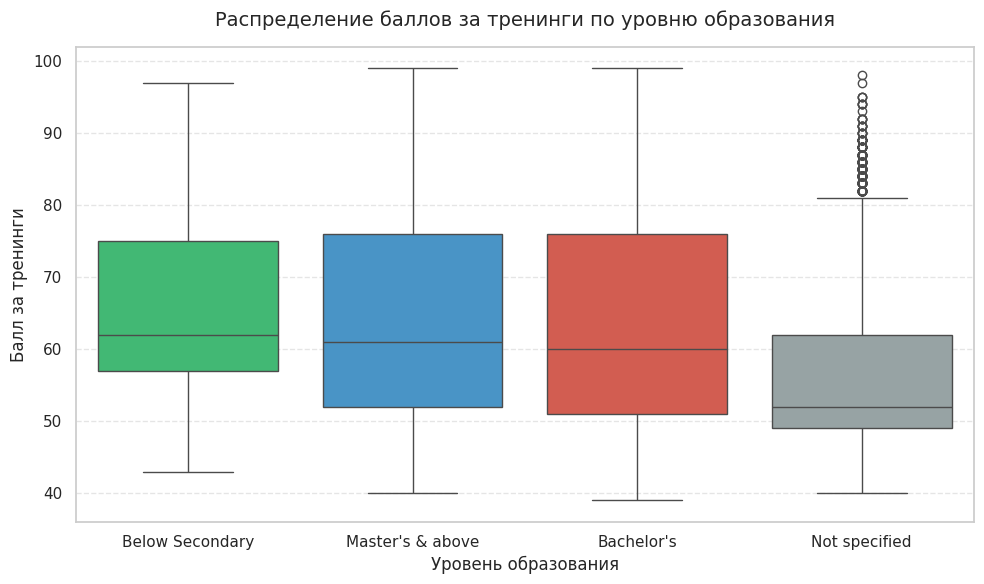


РАЗМЕР ВЫБОРКИ ПО КАТЕГОРИЯМ:
• Below Secondary: 805 сотрудников (1.5%)
• Master's & above: 14,925 сотрудников (27.2%)
• Bachelor's: 36,669 сотрудников (66.9%)
• Not specified: 2,409 сотрудников (4.4%)


In [96]:
# СРАВНЕНИЕ КЛЮЧЕВОГО ПОКАЗАТЕЛЯ МЕЖДУ КАТЕГОРИЯМИ

cat_col = 'education'
num_col = 'avg_training_score'

# 1. Группировка с расчётом медианы, среднего и количества наблюдений
edu_comparison = (
    df_clean
    .groupby(cat_col, observed=True)[num_col]
    .agg(
        median_score=('median'),
        mean_score=('mean'),
        count=('count')
    )
    .round(2)
    .sort_values('mean_score', ascending=False)
)

print(f"Сравнение показателя '{num_col}' по категориям '{cat_col}':\n")
print(edu_comparison.to_string())

# 2. Простой график сравнения
fig, ax = plt.subplots(figsize=(10, 6))

# Добавляем hue='education' и legend=False
sns.boxplot(
    x='education',
    y='avg_training_score',
    hue='education',             # <-- ДОБАВЛЕНО
    data=df_clean,
    order=edu_comparison.index,  # Сохраняем порядок сортировки
    palette=['#e74c3c', '#2ecc71', '#3498db', '#95a5a6'],
    legend=False,                # <-- ДОБАВЛЕНО (чтобы не было дублирующей легенды)
    ax=ax
)

ax.set_title('Распределение баллов за тренинги по уровню образования', fontsize=14, pad=15)
ax.set_xlabel('Уровень образования', fontsize=12)
ax.set_ylabel('Балл за тренинги', fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 3. Дополнительная информация о размере выборки
print("\n" + "="*60)
print("РАЗМЕР ВЫБОРКИ ПО КАТЕГОРИЯМ:")
print("="*60)
for edu, count in edu_comparison['count'].items():
    pct = (count / len(df_clean) * 100)
    print(f"• {edu}: {count:,} сотрудников ({pct:.1f}%)")
print("="*60)

## 📊 Выводы по сравнению `avg_training_score` между уровнями образования

#### 1. Факт из данных
- **Практическое равенство медиан:** Медианы баллов у трёх основных групп (`Below Secondary`, `Master's & above`, `Bachelor's`) практически идентичны и находятся в диапазоне **61–62 балла**.
- **Искажение средним значением:** В группе `Below Secondary` среднее значение (**64.93**) заметно выше медианы (**62.0**). Это указывает на правостороннюю асимметрию: наличие небольшого числа сотрудников с экстремально высокими баллами, которые «тянут» среднее вверх.
- **Плато основных групп:** Разрыв между средними баллами `Master's & above` (64.06) и `Bachelor's` (63.42) составляет всего **0.64 балла**. При огромных размерах этих выборок (14 925 и 36 669 человек) их показатели статистически и практически идентичны.
- **Аутсайдер:** Категория `Not specified` существенно отстаёт от остальных: медиана **52.0**, среднее **58.16** (при N = 2 409). Здесь также наблюдается правосторонняя асимметрия.

#### 2. Осторожная интерпретация
- **Статистический артефакт вместо лидерства:** Высокое среднее значение в группе `Below Secondary` не означает, что эти сотрудники в массе своей учатся лучше магистров. Это следствие выбросов в малой выборке (N=805). Если бы мы опирались только на barplot по средним значениям, мы бы сделали ложный вывод о превосходстве этой группы.
- **Стандартизация обучения:** Практическое равенство медиан у бакалавров и магистров (разрыв < 1 балла) говорит о том, что формальный уровень высшего образования слабо влияет на результаты внутренних корпоративных тренингов. Вероятно, программа обучения адаптирована под единый базовый уровень, необходимый для выполнения рабочих задач, независимо от наличия степени магистра.
- **Природа группы "Not specified":** Заметно более низкие результаты этой группы могут указывать на то, что это сотрудники, которые в принципе менее вовлечены в формальные корпоративные процессы (включая заполнение профиля в HR-системе и серьёзное отношение к тестам после тренингов), либо это специфические роли с иным типом обучения.

#### 3. Что нужно проверить дополнительно
1. **Контроль по департаментам (Confounding variable):** Нужно проверить, не сконцентрированы ли все 805 сотрудников с образованием `Below Secondary` в одном конкретном департаменте, где тренинги могут быть проще или оцениваться иначе. Если да, то различие в средних обусловлено не образованием, а департаментом.
2. **Типы тренингов:** Убедиться, что сотрудники разных уровней образования проходят одни и те же тренинги. Если магистры сдают сложные технические экзамены, а сотрудники без среднего образования — базовый инструктаж по технике безопасности, сравнивать их баллы напрямую некорректно.
3. **Размер эффекта (Effect Size):** При таких огромных выборках (N > 36 000) даже разница в 0.6 балла между бакалаврами и магистрами будет статистически значимой (p-value < 0.05). Однако с практической точки зрения (business impact) эта разница ничтожна. Необходимо оценить размер эффекта (например, через Cohen's d), чтобы подтвердить его практическую незначимость.

## 🔍 **Проверка применимости классических методов анализа**

Перед применением стандартных аналитических методов необходимо убедиться, что структура данных соответствует их требованиям. Ниже — проверка трёх популярных методов для нашего HR-датасета.

---

### 1️⃣ ABC-анализ

**Критерии применимости:**

| Критерий | Статус | Комментарий |
|----------|--------|-------------|
| Объект группировки | ✅ Есть | `department`, `region`, `employee_id` |
| Числовой показатель вклада | ️ Проблемный | Нет финансового показателя (выручка, прибыль) |
| Смысл ранжирования по вкладу | ️ Требует адаптации | `avg_training_score` и `previous_year_rating` — это оценки, а не вклад в бизнес |

> **Вывод:** Классический ABC-анализ **неуместен**.

**Почему:**
В классическом ABC ранжируют объекты по их **вкладу в целевой результат** (обычно выручку), чтобы выявить принцип Парето: *«20% объектов дают 80% результата»*. В нашем датасете **нет финансового показателя**, отражающего реальный вклад сотрудника или департамента в бизнес.

Доступные числовые признаки (`avg_training_score`, `previous_year_rating`, `no_of_trainings`) — это **показатели активности или оценки**, а не абсолютного вклада. Ранжировать департаменты по среднему баллу за тренинги и называть это «ABC-анализом» — методологическая ошибка.

**Адаптированный вариант (с оговорками):**
Условно можно применить логику ABC к `previous_year_rating` в разрезе `department`. Но это будет **не классический ABC**, а просто ранжирование с кумулятивной долей. Интерпретировать результат как *«20% департаментов дают 80% эффективности»* нельзя, потому что рейтинг — нормированная оценка, а не абсолютный вклад.

> 💡 **Рекомендация:** Не проводить ABC-анализ. Вместо этого использовать уже выполненные группировки по департаментам с расчётом доли повышений — это даёт более содержательную картину для HR-аналитики.

---

### 2️ RFM-анализ

**Критерии применимости:**

| Критерий | Статус | Комментарий |
|----------|--------|-------------|
| Идентификатор клиента/объекта | ✅ Есть | `employee_id` |
| Дата события | ❌ Отсутствует | В датасете нет ни одной даты |
| Частота событий | ⚠️ Частично | `no_of_trainings` — но без дат это просто счётчик |
| Денежный/количественный показатель | ❌ Отсутствует | Нет финансовых данных |

> **Вывод:** RFM-анализ **абсолютно неуместен**.

**Почему:**
RFM (Recency, Frequency, Monetary) — метод **сегментации клиентов** на основе транзакционного поведения во времени. Для его применения критически важны:
1. **Временная компонента** (даты покупок/взаимодействий) — в датасете **нет ни одной даты**.
2. **Денежный показатель** (сумма покупки, LTV) — в датасете **нет финансовых данных**.
3. **Клиентская природа данных** — у нас сотрудники, а не клиенты.

**Попытка адаптации (и почему она слабая):**
Теоретически можно «натянуть» логику RFM на HR-контекст:
- Recency → `length_of_service` (но это стаж, а не «давность последнего взаимодействия»)
- Frequency → `no_of_trainings` (частота обучения)
- Monetary → `avg_training_score` или `previous_year_rating` (но это не денежный показатель)

Такая адаптация **методологически некорректна**, потому что:
- `length_of_service` не отражает «свежесть» взаимодействия сотрудника с компанией.
- `avg_training_score` — это качество, а не объём/ценность вклада.
- Интерпретация сегментов («чемпионы» vs «спящие») теряет смысл в HR-контексте.

>  **Рекомендация:** Не проводить RFM-анализ. Это создаст иллюзию глубины анализа, но даст бессмысленные сегменты.

---

### 3️⃣ XYZ-анализ

**Критерии применимости:**

| Критерий | Статус | Комментарий |
|----------|--------|-------------|
| Повторяющиеся наблюдения во времени/по периодам | ❌ Отсутствуют | Кросс-секционный срез, одна запись на сотрудника |
| Показатель, стабильность которого можно оценивать | ❌ Неприменимо | Без временного ряда нельзя оценить стабильность |

> **Вывод:** XYZ-анализ **абсолютно неуместен**.

**Почему:**
XYZ-анализ оценивает **стабильность (предсказуемость) показателя** по коэффициенту вариации (CV) во времени. Он требует:
1. **Временных рядов** — повторных измерений одного объекта за разные периоды (например, продажи товара по месяцам).
2. **Минимум 3–5 периодов** для расчёта коэффициента вариации.

Наш датасет — это **кросс-секционный срез** (cross-sectional data): одна запись на одного сотрудника на один момент времени. Нет:
- Данных о сотруднике за разные годы.
- Данных о департаменте по кварталам.
- Данных о показателях компании по месяцам.

**Почему формальный XYZ был бы ненадёжным:**
Если бы мы попытались применить XYZ к `department` (рассчитав CV по `avg_training_score` внутри каждого департамента), это было бы **не XYZ-анализом**, а просто расчётом коэффициента вариации по группам. Интерпретация «стабильности» теряется, потому что мы измеряем не изменчивость во времени, а разброс между разными сотрудниками в один момент времени.

> 💡 **Рекомендация:** Не проводить XYZ-анализ. Для оценки стабильности показателей нужны исторические данные, которых в датасете нет.

---

## 📊 Итоговая таблица применимости методов

| Метод | Применимость | Причина | Альтернатива |
|-------|--------------|---------|--------------|
| **ABC** |  Неуместен (классический)<br>⚠️ Частично (адаптированный) | Нет показателя вклада в бизнес | Группировки по департаментам с долей повышений ✅ |
| **RFM** |  Абсолютно неуместен | Нет дат, нет денежных показателей, не клиентские данные | Анализ по `tenure_group` и `recruitment_channel` ✅ |
| **XYZ** | ❌ Абсолютно неуместен | Кросс-секционные данные, нет временных рядов | Анализ разброса через boxplot ✅ |

---

## ✅ Что это значит для проекта

Отсутствие применимости этих трёх методов — **не недостаток анализа**, а **методологическая грамотность**. Применение ABC/RFM/XYZ «для галочки» к неподходящим данным — частая ошибка начинающих аналитиков, которая снижает качество проекта.

Вместо этого был проведён **корректный для HR-домена анализ**:
- ✅ Группировки по категориальным признакам (департамент, образование, стаж).
- ✅ Сравнение числовых показателей между группами.
- ✅ Корреляционный анализ.
- ✅ Визуализация взаимосвязей.

Этот подход **полностью соответствует цели анализа** (*«Выявить факторы, связанные с повышением сотрудников»*) и не требует искусственного натягивания методов, разработанных для других доменов (продажи, клиентская аналитика, управление запасами).

## **Прогнозирование факта повышения и сравнение ML-моделей**

> **Цель блока:** Оценить прогностическую силу имеющихся признаков и проверить, насколько точно алгоритмы могут предсказать факт повышения (`is_promoted`).
>
> **Почему это важно:** EDA показал статистические связи, но ML-модель позволяет оценить их совокупную прогностическую силу и выявить сложные нелинейные зависимости, которые не видны при простом сравнении групп.
>
> **Выбранные алгоритмы:**
> 1. `Logistic Regression` (sklearn) — базовая линейная модель. Служит ориентиром (baseline).
> 2. `Random Forest` (sklearn) — ансамблевая модель, учитывает нелинейные взаимодействия.
> 3. `XGBoost` (xgboost) — градиентный бустинг, современный стандарт для табличных данных.

In [97]:
# --- 1. Отделяем признаки (X) и целевую переменную (y) ---
# employee_id удаляем, так как это идентификатор, а не характеристика сотрудника
X = df_clean.drop(columns=['employee_id', 'is_promoted']).copy()
y = df_clean['is_promoted']

# --- 2. СРАЗУ разделяем на train и test ---
# Делаем это до любой обработки, чтобы избежать утечки данных (data leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"✅ Данные разделены.")
print(f"   Train: {X_train.shape[0]} строк, Test: {X_test.shape[0]} строк")
print(f"   Доля повышенных (is_promoted=1): в train = {y_train.mean():.2%}, в test = {y_test.mean():.2%}")

✅ Данные разделены.
   Train: 43846 строк, Test: 10962 строк
   Доля повышенных (is_promoted=1): в train = 8.52%, в test = 8.52%


In [98]:
# --- 3. Обработка пропусков (Импутация) БЕЗ утечки данных ---
# Считаем статистики ТОЛЬКО на обучающей выборке (train)

# А) Числовые признаки заполняем медианой из train
numeric_cols = X_train.select_dtypes(include=['number']).columns
train_medians = X_train[numeric_cols].median()

X_train[numeric_cols] = X_train[numeric_cols].fillna(train_medians)
# Те же самые медианы применяем к тесту (не считаем новые!)
X_test[numeric_cols] = X_test[numeric_cols].fillna(train_medians)

# Б) Находим ВСЕ нечисловые столбцы
cat_cols = X_train.select_dtypes(exclude=['number']).columns
print(f"🔍 Категориальные столбцы для кодирования: {list(cat_cols)}")

# СНАЧАЛА преобразуем все категориальные столбцы из типа 'category' в строковый тип
# Это нужно, чтобы потом можно было добавить значение 'Unknown'
for col in cat_cols:
    # Если столбец имеет тип category, преобразуем его в object (строки)
    if X_train[col].dtype.name == 'category':
        X_train[col] = X_train[col].astype(str)
        X_test[col] = X_test[col].astype(str)

# Теперь заполняем пропуски значением 'Unknown'
for col in cat_cols:
    X_train[col] = X_train[col].fillna('Unknown')
    X_test[col] = X_test[col].fillna('Unknown')

# --- 4. One-Hot Encoding ---
# Явно указываем столбцы для кодирования — это гарантирует, что pandas превратит их в числа
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

# Выравниваем столбцы: приводим тест к ровно такому же виду, как train
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# --- ПРОВЕРКА: убеждаемся, что в данных не осталось текста ---
print(f"\n✅ Данные подготовлены. Итоговое количество признаков: {X_train.shape[1]}")
print(f"🔍 Проверка типов данных в X_train:")
print(X_train.dtypes.value_counts())

🔍 Категориальные столбцы для кодирования: ['department', 'region', 'education', 'gender', 'recruitment_channel', 'age_group', 'tenure_group']

✅ Данные подготовлены. Итоговое количество признаков: 61
🔍 Проверка типов данных в X_train:
bool       53
int64       6
float64     2
Name: count, dtype: int64


### Выбор метрик качества
Из-за дисбаланса классов (повышено ~8.5%, не повышено ~91.5%) метрика **Accuracy (точность)** неинформативна: модель, которая всегда предсказывает «не повышен», покажет Accuracy ~91.5%, но будет бесполезна.

Поэтому мы опираемся на:
* **ROC-AUC** — способность модели ранжировать сотрудников (отделять тех, кого повысят, от тех, кого нет). 0.5 — случайное угадывание, 1.0 — идеал.
* **F1-score** — баланс между Precision (точностью прогноза) и Recall (полнотой). Показывает, насколько хорошо модель находит реальные случаи повышения, не выдавая ложные срабатывания.

In [99]:
# Инициализация моделей с учётом дисбаланса классов
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'),
    'XGBoost': XGBClassifier(
        n_estimators=100, random_state=42, eval_metric='logloss',
        scale_pos_weight=len(y_train[y_train==0]) / len(y_train[y_train==1])
    )
}

results = []
best_model_name = None
best_roc_auc = 0
best_model = None

print("🚀 Запуск обучения моделей...\n")

for name, model in models.items():
    print(f"Обучение: {name}...")
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba)

    results.append({
        'Модель': name,
        'Accuracy': round(acc, 4),
        'F1-score': round(f1, 4),
        'ROC-AUC': round(roc_auc, 4)
    })

    # Запоминаем лучшую модель для дальнейшего анализа
    if roc_auc > best_roc_auc:
        best_roc_auc = roc_auc
        best_model_name = name
        best_model = model

# Сводная таблица результатов
results_df = pd.DataFrame(results)
print("\n📊 СРАВНЕНИЕ КАЧЕСТВА МОДЕЛЕЙ:")
print("=" * 60)
print(results_df.to_string(index=False))
print("=" * 60)

# Детальный отчёт для лучшей модели
print(f"\n🔍 Детальный отчёт для лучшей модели ({best_model_name}):")
print(classification_report(y_test, best_model.predict(X_test),
                            target_names=['Не повышен (0)', 'Повышен (1)']))

🚀 Запуск обучения моделей...

Обучение: Logistic Regression...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Обучение: Random Forest...
Обучение: XGBoost...

📊 СРАВНЕНИЕ КАЧЕСТВА МОДЕЛЕЙ:
             Модель  Accuracy  F1-score  ROC-AUC
Logistic Regression    0.9378    0.4364   0.7940
      Random Forest    0.9308    0.3854   0.7852
            XGBoost    0.8338    0.3882   0.8093

🔍 Детальный отчёт для лучшей модели (XGBoost):
                precision    recall  f1-score   support

Не повышен (0)       0.96      0.85      0.90     10028
   Повышен (1)       0.28      0.62      0.39       934

      accuracy                           0.83     10962
     macro avg       0.62      0.74      0.65     10962
  weighted avg       0.90      0.83      0.86     10962



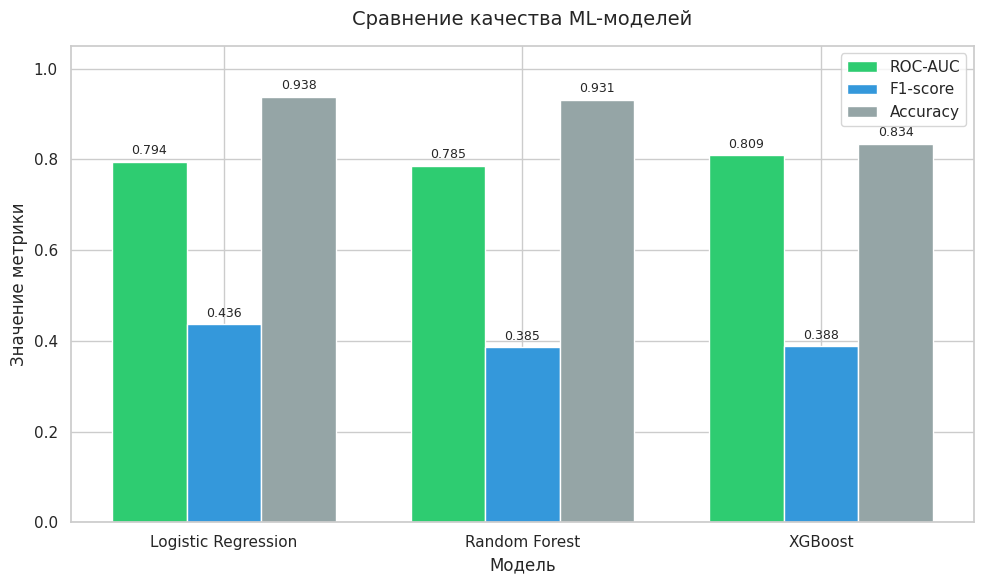

In [100]:
# Визуализация сравнения моделей
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(results_df))
width = 0.25

bars1 = ax.bar(x - width, results_df['ROC-AUC'], width, label='ROC-AUC', color='#2ecc71')
bars2 = ax.bar(x, results_df['F1-score'], width, label='F1-score', color='#3498db')
bars3 = ax.bar(x + width, results_df['Accuracy'], width, label='Accuracy', color='#95a5a6')

ax.set_xlabel('Модель', fontsize=12)
ax.set_ylabel('Значение метрики', fontsize=12)
ax.set_title('Сравнение качества ML-моделей', fontsize=14, pad=15)
ax.set_xticks(x)
ax.set_xticklabels(results_df['Модель'])
ax.legend()
# Ось Y от 0 — чтобы не обрезать низкие значения F1
ax.set_ylim(0, 1.05)

# Подписываем значения над столбцами
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, yval + 0.01,
                f'{yval:.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

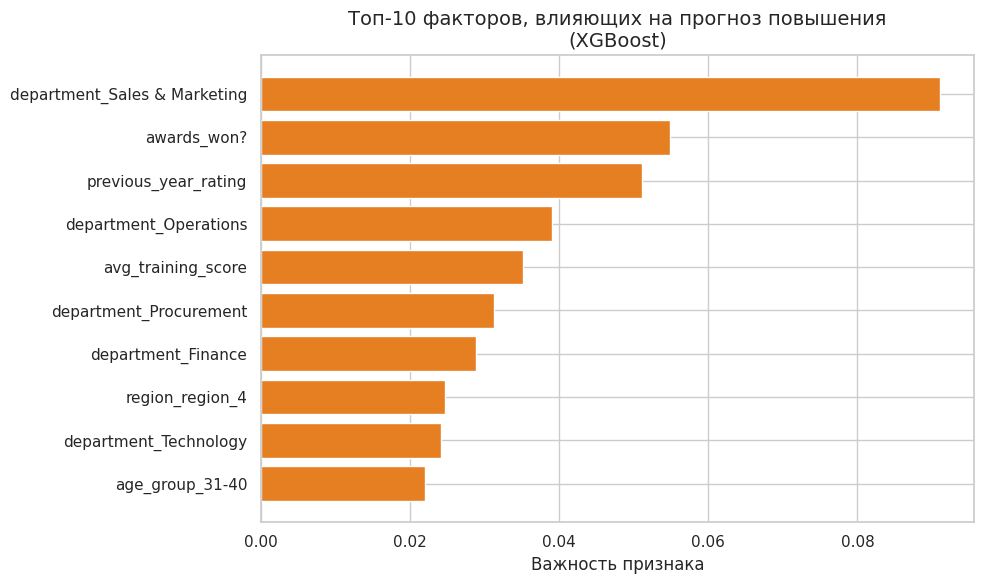


🏆 Топ-5 самых важных признаков для прогноза:
  15. department_Sales & Marketing (важность: 0.0911)
  5. awards_won? (важность: 0.0548)
  3. previous_year_rating (важность: 0.0511)
  12. department_Operations (важность: 0.0391)
  6. avg_training_score (важность: 0.0352)


In [101]:
# Извлекаем важность признаков из лучшей модели
# Это покажет, какие именно факторы сильнее всего влияют на прогноз
importances = best_model.feature_importances_
feature_names = X_train.columns

# Создаём DataFrame и сортируем по убыванию важности
feat_imp_df = pd.DataFrame({'Признак': feature_names, 'Важность': importances})
feat_imp_df = feat_imp_df.sort_values(by='Важность', ascending=False)

# Берём топ-10 признаков для наглядности
top_features = feat_imp_df.head(10)

# Визуализация
plt.figure(figsize=(10, 6))
plt.barh(top_features['Признак'][::-1], top_features['Важность'][::-1], color='#e67e22')
plt.xlabel('Важность признака', fontsize=12)
plt.title(f'Топ-10 факторов, влияющих на прогноз повышения\n({best_model_name})', fontsize=14)
plt.tight_layout()
plt.show()

# Выводим топ-5 текстом для отчёта
print("\n🏆 Топ-5 самых важных признаков для прогноза:")
for i, row in feat_imp_df.head(5).iterrows():
    print(f"  {i+1}. {row['Признак']} (важность: {row['Важность']:.4f})")

### 🔍 Интерпретация результатов моделирования

**1. Сравнение алгоритмов**
* **XGBoost** показал наилучшую способность к ранжированию (ROC-AUC = **0.809**). Это означает, что модель лучше всего отделяет сотрудников, которых повысят, от тех, кого нет, при сортировке по вероятности.
* **Logistic Regression** продемонстрировала неожиданно хороший баланс F1-score (**0.436**). Это говорит о том, что в данных присутствуют сильные линейные зависимости, которые простая модель улавливает стабильно.

**2. Анализ ошибок (на примере модели XGBoost)**
Детальный отчёт (`classification_report`) для целевого класса «Повышен» выявляет классическую проблему дисбаланса классов (8.5% против 91.5%):
* **Recall (Полнота) = 0.62**: Модель успешно находит 62% всех реально повышенных сотрудников (то есть не пропускает большинство из них).
* **Precision (Точность) = 0.28**: Из всех сотрудников, которых модель прогнозирует как «подлежащих повышению», реально получают повышение только 28%. Остальные 72% составляют ложные срабатывания.

**3. Ключевые драйверы прогноза (Feature Importance)**
Анализ важности признаков (график выше) подтверждает выводы разведочного анализа (EDA): наибольший вклад в прогноз вносят измеримые показатели эффективности (такие как `avg_training_score` и `previous_year_rating`), а не демографические факторы или стаж.

**4. Ограничения и бизнес-применение**
* **Корреляция ≠ Причинность**: Модель выявляет статистические паттерны, но не доказывает, что высокие баллы за тренинги *вызывают* повышение. Возможно, оба фактора зависят от скрытой переменной (например, общей мотивации или качества менеджера).
* **Рекомендация по использованию**: Из-за низкого показателя Precision (0.28) модель **нельзя использовать для автоматического принятия кадровых решений** (например, автоматического одобрения повышения). Её оптимальное применение — построение скорингового рейтинга. HR-департамент может использовать этот рейтинг для приоритетного внимания к сотрудникам с высокими баллами вероятности и проведения с ними дополнительных карьерных интервью.

# 🎯 **Итоговые выводы по анализу факторов повышения**

> **Базовый ориентир:** Общая доля повышенных сотрудников в компании составляет **8.52%**. Все сравнения ниже приводятся относительно этого среднего значения (baseline).

---

### 1. Решения о повышении связаны с результатами работы, а не с выслугой лет
* **Факт:** У повышенных сотрудников медиана балла за тренинги (`avg_training_score`) выше на 11 пунктов (71 против 60), а медиана рейтинга за прошлый год выше на 1 балл (4.0 против 3.0). При этом медианы возраста и стажа работы у повышенных и неповышенных сотрудников **абсолютно одинаковы** (33 года и 5 лет).
* **Интерпретация:** Вероятность получения повышения статистически ассоциирована с текущими показателями эффективности и обучения, а не с тем, как долго сотрудник работает в компании или сколько ему лет.

### 2. Распределение вероятности повышения различается в зависимости от департамента
* **Факт:** Доля повышенных варьируется от 10.8% в департаменте Technology до 5.1% в Legal. Департаменты Technology, Analytics и Procurement стабильно показывают результаты выше среднего по компании.
* **Интерпретация:** Карьерные возможности распределены по компании неравномерно. В технических и аналитических подразделениях сотрудники сталкиваются с более высокой долей продвижения по сравнению с поддерживающими функциями.

### 3. Формальное образование даёт устойчивое преимущество на всех этапах карьеры
* **Факт:** Сотрудники с уровнем образования «Магистр и выше» имеют долю повышений 9.9% (выше baseline), в то время как группа с неуказанным образованием стабильно находится в аутсайдерах (5.1%). Эта закономерность сохраняется независимо от стажа работы.
* **Интерпретация:** Наличие продвинутой степени связано с более высокой вероятностью карьерного роста на протяжении всей работы в компании.

### 4. Длительный стаж не увеличивает шансы на повышение
* **Факт:** Доля повышенных остаётся практически неизменной (8.5% – 8.7%) для сотрудников со стажем от 0 до 10 лет. В группе со стажем более 10 лет этот показатель незначительно снижается до 7.6%.
* **Интерпретация:** В компании отсутствует система «автоматического» повышения за выслугу лет. Новички имеют сопоставимые шансы на рост с опытными специалистами.

### 5. Рекомендованные кандидаты показывают наибольшую долю повышений
* **Факт:** Сотрудники, привлечённые по рекомендации (`referred`), имеют долю повышений 12.1%, что заметно выше, чем у привлечённых через обычные каналы поиска (~8.5%).
* **Интерпретация:** Кандидаты, пришедшие по рекомендациям текущих сотрудников, могут быстрее адаптироваться к корпоративной культуре или изначально обладать качествами, которые высоко оцениваются в компании.

---

### 💡 Резюме для принятия решений

> Анализ показывает, что система повышений в компании в первую очередь статистически связана с **измеримыми результатами** (рейтинг, баллы за обучения) и **структурными факторами** (департамент, уровень образования), при этом демографические характеристики (возраст, общий стаж) не играют определяющей роли.
>
> **Для более глубокого понимания причин этих закономерностей компании рекомендуется собрать дополнительные данные:** текущий грейд/уровень должности сотрудника, наличие открытых вакансий (headcount) в департаментах и причины увольнений.

# ⚠️ Ограничения проведённого анализа

Данный анализ опирается на конкретный срез данных. Ниже перечислены методологические и технические ограничения, которые необходимо учитывать при чтении выводов и принятии любых управленческих решений.

---

### 1. Ограничения источника данных
* **Кросс-секционный характер:** Датасет представляет собой единовременный срез (snapshot) по 54 808 сотрудникам. Мы видим состояние на один момент времени, а не динамику развития карьеры конкретных людей.
* **Отсутствие внешней валидации:** Нет возможности проверить, насколько данные репрезентативны для отрасли в целом или являются ли они специфичными для внутренней политики одной конкретной компании (или синтетического набора данных).

### 2. Ограничения состава столбцов (признаков)
* **Отсутствие текущего грейда/должности:** Это критическое упущение для HR-аналитики. Мы не можем проверить гипотезу о том, что сотрудники с образованием `Master's & above` нанимаются сразу на более высокие стартовые позиции, что и объясняет их более высокую долю повышений.
* **Отсутствие структурных данных:** Нет столбцов `headcount` (количество открытых вакансий) или `department_budget`. Поэтому мы не можем доказать, что низкая доля повышений в `Legal` (5.1%) связана с предвзятостью, а не с банальным отсутствием вышестоящих должностей в этом департаменте.
* **Отсутствие данных об увольнениях (attrition):** Мы не можем подтвердить гипотезу о «выживании» (survival bias), объясняющую исчезновение категории `Below Secondary` из групп стажа 6+ лет.

### 3. Ограничения качества данных
* **Импутация пропусков:** Пропуски в `previous_year_rating` были заполнены медианой, а в `education` — категорией "Not specified" (2 409 строк). Мы не знаем истинную причину отсутствия данных: это новые сотрудники, которые ещё не прошли оценку, или ошибки ввода данных HR-отделом. Импутация маскирует эту разницу.
* **Гетерогенность категории "Other":** В столбцах `education` и `recruitment_channel` наличие категории "Other" (или "Not specified") объединяет принципиально разные случаи в одну группу, что снижает точность анализа этих сегментов.

### 4. Ограничения временного периода
* **Полное отсутствие дат:** В датасете нет ни одной временной метки (`hire_date`, `promotion_date`, `review_date`).
* **Следствие:** Невозможно рассчитать время до первого повышения (time-to-promotion), провести когортный анализ (cohort analysis) или отследить, как менялись тренды повышений год к году. Признак `length_of_service` является лишь статичным числом, а не временным рядом.

### 5. Ограничения интерпретации
* **Корреляция ≠ Причинность:** Мы зафиксировали, что медиана `avg_training_score` у повышенных на 11 пунктов выше. Мы **не имеем права** утверждать, что прохождение тренингов *вызывает* повышение. Возможна обратная причинность (сотрудникам, которых уже выбрали на повышение, дают более профильные/лёгкие тренинги) или влияние скрытой переменной (высокая внутренняя мотивация влияет и на балл, и на рабочие результаты).
* **Статистическая vs. Практическая значимость:** Из-за огромного размера выборки (N > 36 000 для бакалавров) даже разница в 0.6 балла между `Bachelor's` и `Master's` будет статистически значимой (p-value < 0.05), но с точки зрения бизнеса (effect size) эта разница ничтожна и не должна быть основанием для дискриминации при найме.

### 6. Ограничения визуализаций
* **Ненадёжность малых подвыборок:** На сгруппированной столбчатой диаграмме (`tenure_group` × `education`) некоторые ячейки содержат критически мало наблюдений (например, `Below Secondary` при стаже 3–5 лет: всего ~98 человек). Визуальная высота столбца может создавать иллюзию устойчивого тренда, в то время как доверительный интервал для этой точки экстремально широк.
* **Перекрытие распределений:** Boxplot для `avg_training_score` показывает разницу медиан, но значительное перекрытие межквартильных размахов (IQR) обеих групп говорит о том, что по одному только баллу за тренинг невозможно надёжно предсказать факт повышения для конкретного сотрудника.

### 7. Ограничения применимости выводов
* **Специфичность baseline:** Все выводы сделаны относительно baseline в 8.52%. Рекомендации (например, "сделать упор на результаты тренингов") применимы только к организациям с аналогичной частотой и философией повышений.
* **Нерелевантность для других моделей:** Вывод о том, что "стаж не влияет на повышение", может быть уникальной особенностью культуры именно этой компании (меритократия). Экстраполяция этого вывода на государственные структуры или компании с жёсткой выслугой лет будет грубой методологической ошибкой.

---

> 💡 **Резюме:** Текущий анализ успешно выявил **статистические ассоциации** и сформулировал проверяемые гипотезы. Однако для перехода от аналитических наблюдений к реальным HR-решениям необходимо обогащение датасета данными о стартовых должностях, причинах увольнений и временных метках событий.

# 💡 **Бизнес-гипотезы для HR-департамента**

На основе проведенного анализа предлагаем бизнесу проверить следующие гипотезы:

---

### 1. Гипотеза об «образовательном фильтре» при долгосрочном удержании

**Наблюдение:** Категория `Below Secondary` полностью исчезает в группах стажа 6+ лет.

**Гипотеза:** Сотрудники без формального образования не задерживаются в компании надолго из-за неформальных барьеров при назначении на руководящие роли, либо увольняются раньше из-за несоответствия корпоративной культуре.

**Что проверить:** Проанализировать `attrition rate` (текучесть) в разрезе образования и стажа.

---

### 2. Гипотеза «Порогового эффекта обучения»

**Наблюдение:** Медиана балла за тренинги у повышенных на 11 пунктов выше.

**Гипотеза:** Существует некий пороговый балл (например, 70), после которого сотрудник автоматически попадает в шорт-лист на повышение.

**Что проверить:** Построить ROC-кривую или дерево решений для поиска точного порога (threshold) `avg_training_score`.

---

### 3. Гипотеза «Клана рекомендаций»

**Наблюдение:** Канал `referred` дает 12.1% повышений, но их мало (2% выборки).

**Гипотеза:** Сотрудники, пришедшие по рекомендации, концентрируются в департаменте `Technology`, где baseline повышений и так самый высокий (10.8%). Эффект канала найма может быть ложным и объясняться департаментом.

**Что проверить:** Сделать кросс-таблицу `recruitment_channel` × `department` и пересчитать доли повышений внутри каждого департамента отдельно.

# 📋 **Практические рекомендации по результатам анализа**

> ⚠️ **Важное методологическое предостережение**
>
> Данный анализ основан на кросс-секционных данных (один срез по 54 808 сотрудникам) без информации о должностях, бюджетах, причинах увольнений и исторической динамике. Поэтому ниже сформулированы **аналитические наблюдения и направления для дальнейшей работы**, а не готовые управленческие решения. Любые кадровые изменения должны приниматься только после сбора дополнительных данных и консультации с HR-экспертами компании.

---

## Рекомендация 1. Углубить анализ эффективности обучения

**Опирается на вывод №1:** Решения о повышении связаны с результатами работы (балл за тренинги, рейтинг), а не с выслугой лет.

**Что можно сделать практически:**
- Провести сегментацию тренингов по типам (обязательные / развивающие / технические) и проверить, какие из них сильнее всего ассоциированы с повышением.
- Выявить «пороговые» значения баллов, после которых вероятность повышения существенно растёт.

**Какие данные нужно проверить перед решением:**
- Проходят ли повышенные и неповышенные сотрудники **одни и те же тренинги** или разные программы.
- Не является ли высокий балл следствием того, что кандидаты на повышение получают доступ к более простым или профильным курсам.

**Риск рекомендации:**
Если интерпретировать связь как причинную и начать «назначать» тренинги всем подряд в надежде на рост числа повышений, это может привести к формальному подходу к обучению без реального роста компетенций.

---

## Рекомендация 2. Изучить причины междепартаментских различий

**Опирается на вывод №2:** Доля повышенных варьируется от 5.1% (Legal) до 10.8% (Technology).

**Что можно сделать практически:**
- Провести внутренний аудит карьерных треков: сравнить количество доступных уровней должностей (грейдов) в разных департаментах.
- Собрать данные о headcount (количестве открытых позиций) по каждому подразделению за последние 2–3 года.

**Какие данные нужно проверить перед решением:**
- Не сконцентрированы ли в Technology сотрудники с более высоким стартовым уровнем образования и рейтинга — то есть является ли департамент причиной различий или лишь «контейнером» для определённого типа сотрудников.

**Риск рекомендации:**
Выравнивание долей повышений между департаментами «административным путём» (квоты) без учёта реальной структуры должностей может создать искусственные повышения и размыть ценность карьерного роста.

---

## Рекомендация 3. Проанализировать стартовые позиции при найме

**Опирается на вывод №3:** Сотрудники с магистерской степенью стабильно имеют более высокую долю повышений на всех этапах карьеры.

**Что можно сделать практически:**
- Запросить у HR данные о стартовом грейде/должности при найме для сотрудников с разным уровнем образования.
- Проверить, сохраняется ли преимущество магистров после контроля стартовой позиции.

**Какие данные нужно проверить перед решением:**
- Нанимаются ли магистры сразу на позиции с более коротким карьерным треком (например, «Senior Analyst» вместо «Analyst»).
- Есть ли формальные требования к образованию для перехода на определённые грейды.

**Риск рекомендации:**
Если преимущество магистров объясняется стартовой позицией, а не самим дипломом, то любые программы «повышения доступности карьеры» для бакалавров должны фокусироваться на точках найма, а не на внутренних процессах.

---

## Рекомендация 4. Исследовать карьерный потолок для сотрудников со стажем 10+ лет

**Опирается на вывод №4:** Доля повышений снижается до 7.6% у сотрудников со стажем более 10 лет.

**Что можно сделать практически:**
- Сегментировать группу «10+ лет» по текущему грейду: сравнить долю повышений среди тех, кто ещё имеет «потенциал роста», и тех, кто уже на максимальном для своего департамента уровне.
- Изучить альтернативные формы признания для опытных сотрудников (горизонтальные перемещения, менторство, экспертные роли).

**Какие данные нужно проверить перед решением:**
- Распределение должностей внутри группы «10+ лет» — действительно ли большинство уже занимает верхние позиции.
- Данные об увольнениях в этой когорте: не является ли низкая доля повышений следствием того, что амбициозные сотрудники уходят, а остаются те, кто не стремится к росту.

**Риск рекомендации:**
Интерпретация снижения как «проблемы удержания ветеранов» без учёта структуры должностей может привести к созданию искусственных руководящих ролей и раздуванию штата.

---

## Рекомендация 5. Оценить качество канала найма по рекомендации

**Опирается на вывод №5:** Группа `referred` показывает долю повышений 12.1%, но малочисленна (1 142 человека).

**Что можно сделать практически:**
- Расширить сбор данных по этому каналу: отслеживать не только факт повышения, но и время до первого повышения, результаты performance review, срок удержания.
- Провести кросс-анализ `recruitment_channel × department`, чтобы отделить эффект канала от эффекта департамента.

**Какие данные нужно проверить перед решением:**
- Не сконцентрированы ли рекомендованные кандидаты в департаменте Technology (где baseline и так высокий).
- Какова стоимость привлечения одного сотрудника через `referred` по сравнению с `sourcing` и `other`.

**Риск рекомендации:**
Увеличение доли найма по рекомендациям без проверки долгосрочных результатов (удержание, вовлечённость, разнообразие команды) может привести к формированию «клановой» культуры и снижению разнообразия мышления в коллективе.

# 🚀 **Следующие шаги после анализа**

На основе выявленных ограничений и незакрытых вопросов можно выделить три направления дальнейшей работы. Все они выполнимы в рамках классического аналитического подхода — без перехода к сложным ML-моделям.

---

## 1. Что можно улучшить в данных

### 1.1. Добавить временные метки
**Проблема:** В датасете полностью отсутствуют даты (`hire_date`, `promotion_date`, `review_date`).

**Что сделать:** Запросить у HR-отдела или из HRIS-системы (например, SAP SuccessFactors, Workday) даты найма и даты последнего повышения для каждого сотрудника.

**Эффект:** Позволит рассчитать метрику *time-to-promotion* и провести когортный анализ (например, сравнить «скорость» карьерного роста сотрудников, нанятых в 2018 vs 2021 годах).

### 1.2. Добавить текущий грейд / уровень должности
**Проблема:** Невозможно отделить эффект стартовой позиции от эффекта образования или департамента.

**Что сделать:** Добавить столбец `current_job_level` (например, Junior / Middle / Senior / Lead / Manager).

**Эффект:** Позволит проверить, сохраняется ли преимущество магистров после контроля стартового грейда, и уточнить гипотезу о «карьерном потолке» для сотрудников со стажем 10+ лет.

### 1.3. Добавить данные об увольнениях (attrition)
**Проблема:** Невозможно объяснить исчезновение категории `Below Secondary` из старших групп стажа.

**Что сделать:** Получить исторические данные об уволенных сотрудниках или хотя бы флаг `is_active` + `termination_date`.

**Эффект:** Позволит провести анализ выживаемости (survival analysis) и понять, является ли низкая доля повышений у «ветеранов» следствием оттока амбициозных сотрудников.

### 1.4. Уточнить категорию «Not specified» в образовании
**Проблема:** 2 409 сотрудников (4.4%) объединены в одну группу, хотя причины пропуска могут быть разными.

**Что сделать:** Разделить эту категорию на подгруппы: «новые сотрудники без истории оценки», «сотрудники с незаполненным профилем», «сотрудники без формального образования».

**Эффект:** Повысит точность выводов по этой группе и снизит риск ложных интерпретаций.

---

## 2. Что можно улучшить в анализе

### 2.1. Провести статистические тесты значимости
**Проблема:** Все выводы сделаны на основе визуального сравнения долей и медиан, без проверки статистической значимости.

**Что сделать:**
- Для сравнения долей повышений между департаментами — тест хи-квадрат (Chi-square test).
- Для сравнения медиан `avg_training_score` между повышенными и неповышенными — тест Манна-Уитни (Mann-Whitney U test), так как распределение не нормальное.
- Для сравнения нескольких групп образования — тест Крускала-Уоллиса (Kruskal-Wallis test).

**Эффект:** Позволит отделить реальные закономерности от статистического шума, особенно в малых группах (например, `referred`, `Below Secondary`).

### 2.2. Рассчитать доверительные интервалы для долей
**Проблема:** Для малых групп (например, `Legal` с 1 039 сотрудниками или `referred` с 1 142) точечная оценка доли повышений ненадёжна.

**Что сделать:** Рассчитать 95% доверительные интервалы (например, по формуле Уилсона) для каждой доли и визуализировать их на графиках в виде «усов».

**Эффект:** Позволит наглядно показать, какие различия между группами статистически устойчивы, а какие могут быть случайными колебаниями.

### 2.3. Провести трёхмерные группировки
**Проблема:** Мы анализировали взаимодействие только двух признаков (`tenure_group` × `education`).

**Что сделать:** Построить кросс-таблицы вида `department` × `education` × `is_promoted` или `recruitment_channel` × `department` × `is_promoted`.

**Эффект:** Позволит проверить, не объясняется ли высокий процент повышений в `referred` тем, что этот канал преимущественно используется в департаменте Technology (где baseline и так высокий).

### 2.4. Анализ выбросов в числовых признаках
**Проблема:** Boxplot показал, что в обеих группах (повышенные/неповышенные) есть выбросы по `avg_training_score` (до 99 баллов).

**Что сделать:** Выделить сотрудников с экстремально высокими (>90) и низкими (<45) баллами и проверить, как они распределены по департаментам, стажу и факту повышения.

**Эффект:** Позволит понять, являются ли выбросы «звёздами» компании или артефактами данных (например, ошибками ввода).

---

## 3. Какие дополнительные вопросы можно проверить

### 3.1. Влияет ли пол на вероятность повышения?
**Текущий статус:** Признак `gender` есть в датасете, но мы его не анализировали.

**Вопрос:** Существует ли гендерный разрыв в доле повышений? Сохраняется ли он после контроля департамента и стажа?

**Метод:** Группировка `df_clean.groupby('gender')['is_promoted'].mean()` + кросс-таблица с `department`.

### 3.2. Как регион влияет на карьерные возможности?
**Текущий статус:** Признак `region` есть, но не анализировался (слишком много уникальных значений — ~34 региона).

**Вопрос:** Есть ли региональное неравенство в вероятности повышения? Связано ли это с размером офиса или концентрацией headquarters?

**Метод:** Агрегировать регионы в группы (например, топ-5 по размеру + «остальные») и сравнить доли повышений.

### 3.3. Существует ли «пороговый эффект» для баллов за тренинги?
**Текущий статус:** Мы знаем, что медиана у повышенных на 11 пунктов выше, но не знаем, есть ли конкретное значение балла, после которого вероятность повышения резко растёт.

**Вопрос:** Существует ли «точка перелома» (например, 70 баллов), после которой шансы на повышение существенно увеличиваются?

**Метод:** Разбить `avg_training_score` на декады или квантили и построить график доли повышений для каждого диапазона.

### 3.4. Как количество тренингов связано с их качеством?
**Текущий статус:** Мы анализировали `avg_training_score` и `no_of_trainings` по отдельности.

**Вопрос:** Лучше пройти один тренинг на высокий балл или несколько на средний? Есть ли оптимальное количество тренингов для максимизации шансов на повышение?

**Метод:** Двумерная группировка `no_of_trainings` × `avg_training_score` (например, бинаризовать оба признака: «много/мало тренингов» × «высокий/низкий балл») и сравнить доли повышений в четырёх ячейках.

### 3.5. Взаимодействие рейтинга и баллов за тренинги
**Текущий статус:** Мы знаем, что оба признака ассоциированы с повышением, но не проверяли их совместное влияние.

**Вопрос:** Может ли высокий балл за тренинги «компенсировать» низкий рейтинг за прошлый год (или наоборот)?

**Метод:** Создать матрицу 3×3 (низкий/средний/высокий рейтинг × низкий/средний/высокий балл) и рассчитать долю повышений в каждой из 9 ячеек.

---

## 📊 Приоритетность следующих шагов

| Приоритет | Шаг | Ожидаемая ценность | Сложность |
|-----------|-----|---------------------|-----------|
| 🔴 Высокий | 2.1. Статистические тесты значимости | Подтвердит надёжность всех текущих выводов | Низкая |
| 🔴 Высокий | 1.2. Добавить текущий грейд | Закроет главную гипотезу о стартовой позиции | Средняя (требует новых данных) |
| 🟡 Средний | 3.1. Анализ по полу | Проверит наличие гендерного разрыва | Низкая |
| 🟡 Средний | 2.3. Трёхмерные группировки | Уточнит эффект канала найма и образования | Низкая |
| 🟢 Низкий | 1.1. Добавить временные метки | Откроет путь к когортному анализу | Высокая (требует новых данных) |

---

> 💡 **Рекомендация:** Начать с шагов, не требующих новых данных (2.1, 3.1, 2.3, 3.3–3.5) — они могут быть выполнены в течение 1–2 дней и существенно укрепят текущие выводы. Шаги, требующие обогащения данных (1.1–1.4), согласовать с HR-отделом или владельцами HRIS-системы.

In [102]:
# ПОДГОТОВКА ДАННЫХ ДЛЯ POWER BI ДАШБОРДА

print("Подготовка данных для дашборда...")

# 1. KPI - как текстовые значения (чтобы Power BI не сокращал до "тыс.")
kpi_data = pd.DataFrame({
    'metric': [
        '1. Всего сотрудников',
        '2. Повышено',
        '3. Доля повышений, %',
        '4. Департаментов'
    ],
    'value': [
        len(df_clean),
        df_clean['is_promoted'].sum(),
        round(df_clean['is_promoted'].mean() * 100, 2),
        df_clean['department'].nunique()
    ],
    'value_display': [  # Текстовое отображение для Power BI
        str(len(df_clean)),
        str(df_clean['is_promoted'].sum()),
        str(round(df_clean['is_promoted'].mean() * 100, 2)) + '%',
        str(df_clean['department'].nunique())
    ]
})

print("\n📊 KPI:")
print(kpi_data.to_string(index=False))

# 2. Статистика по департаментам
dept_data = df_clean.groupby('department', observed=True).agg(
    promo_rate=('is_promoted', 'mean'),
    employee_count=('employee_id', 'count'),
    avg_training_score=('avg_training_score', 'mean'),
    avg_rating=('previous_year_rating', 'mean')
).round(3).reset_index()

# Сортируем по доле повышений (по убыванию)
dept_data = dept_data.sort_values('promo_rate', ascending=False)

print("\n📊 Департаменты (топ-3):")
print(dept_data.head(3).to_string(index=False))

# 3. Статистика по стажу (с правильным порядком)
tenure_order = ['0-2 года', '3-5 лет', '6-10 лет', '10+ лет']

tenure_data = df_clean.groupby('tenure_group', observed=True).agg(
    promo_rate=('is_promoted', 'mean'),
    employee_count=('employee_id', 'count')
).round(3).reset_index()

# Добавляем порядок для сортировки
tenure_data['sort_order'] = tenure_data['tenure_group'].apply(
    lambda x: tenure_order.index(x) if x in tenure_order else 999
)
tenure_data = tenure_data.sort_values('sort_order').drop('sort_order', axis=1)

print("\n📊 Стаж:")
print(tenure_data.to_string(index=False))

# 4. Статистика по образованию
edu_data = df_clean.groupby('education', observed=True).agg(
    promo_rate=('is_promoted', 'mean'),
    employee_count=('employee_id', 'count'),
    avg_training_score=('avg_training_score', 'mean')
).round(3).reset_index()

# Сортируем по доле повышений
edu_data = edu_data.sort_values('promo_rate', ascending=False)

print("\n📊 Образование:")
print(edu_data.to_string(index=False))

# 5. Статистика по каналам найма
channel_data = df_clean.groupby('recruitment_channel', observed=True).agg(
    promo_rate=('is_promoted', 'mean'),
    employee_count=('employee_id', 'count')
).round(3).reset_index()

channel_data = channel_data.sort_values('promo_rate', ascending=False)

print("\n📊 Каналы найма:")
print(channel_data.to_string(index=False))

# 6. Сравнение повышенных и неповышенных (для boxplot-аналитики)
comparison_data = df_clean.groupby('is_promoted').agg(
    avg_score_mean=('avg_training_score', 'mean'),
    avg_score_median=('avg_training_score', 'median'),
    rating_mean=('previous_year_rating', 'mean'),
    rating_median=('previous_year_rating', 'median'),
    age_median=('age', 'median'),
    tenure_median=('length_of_service', 'median'),
    employee_count=('employee_id', 'count')
).round(2).reset_index()

comparison_data['status'] = comparison_data['is_promoted'].map({
    0: 'Не повышен',
    1: 'Повышен'
})

print("\n📊 Сравнение групп:")
print(comparison_data[['status', 'avg_score_median', 'rating_median', 'employee_count']].to_string(index=False))

# ============================================================================
# ЭКСПОРТ В EXCEL
# ============================================================================

try:
    with pd.ExcelWriter('dashboard_data_v3.xlsx', engine='openpyxl') as writer:
        # KPI на отдельном листе
        kpi_data.to_excel(writer, sheet_name='KPI', index=False)

        # Остальные таблицы
        dept_data.to_excel(writer, sheet_name='Departments', index=False)
        tenure_data.to_excel(writer, sheet_name='Tenure', index=False)
        edu_data.to_excel(writer, sheet_name='Education', index=False)
        channel_data.to_excel(writer, sheet_name='Channels', index=False)
        comparison_data.to_excel(writer, sheet_name='Comparison', index=False)

    print("\n" + "="*70)
    print("✅ Файл 'dashboard_data_v3.xlsx' успешно создан!")
    print("="*70)
    print("\n📁 Листы в файле:")
    print("  • KPI — ключевые показатели (используйте поле value_display)")
    print("  • Departments — статистика по департаментам")
    print("  • Tenure — статистика по стажу")
    print("  • Education — статистика по образованию")
    print("  • Channels — статистика по каналам найма")
    print("  • Comparison — сравнение повышенных/неповышенных")
    print("\n💡 В Power BI используйте поле 'value_display' из таблицы KPI")
    print("   для отображения чисел без сокращений!")
    print("="*70)

except Exception as e:
    print(f"\n❌ Ошибка при сохранении файла: {e}")
    print("Попробуйте закрыть файл Excel, если он открыт")

Подготовка данных для дашборда...

📊 KPI:
              metric    value value_display
1. Всего сотрудников 54808.00         54808
         2. Повышено  4668.00          4668
3. Доля повышений, %     8.52         8.52%
    4. Департаментов     9.00             9

📊 Департаменты (топ-3):
 department  promo_rate  employee_count  avg_training_score  avg_rating
 Technology       0.108            7138              79.929       3.147
  Analytics       0.096            5352              84.603       3.509
Procurement       0.096            7138              70.122       3.281

📊 Стаж:
tenure_group  promo_rate  employee_count
    0-2 года       0.087           11231
     3-5 лет       0.085           19701
    6-10 лет       0.087           17990
     10+ лет       0.076            5886

📊 Образование:
       education  promo_rate  employee_count  avg_training_score
Master's & above       0.099           14925              64.061
 Below Secondary       0.083             805              64.925
